In [ ]:
import os, glob
import time
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import os,json,time,random,warnings
import torch
import torch.nn as nn
from torch.utils.data import WeightedRandomSampler
from torch.utils.data import TensorDataset,DataLoader
from sklearn.preprocessing import LabelEncoder,label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,roc_curve,precision_recall_curve,auc,matthews_corrcoef,cohen_kappa_score
warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA = pd.read_csv("/content/drive/MyDrive/Network_Intrusion_Combined.csv")

In [ ]:
DATA.shape

(2830743, 79)

In [ ]:
DATA.isnull().sum()

,0
Destination Port,0
Flow Duration,0
Total Fwd Packets,0
Total Backward Packets,0
Total Length of Fwd Packets,0
...,...
Idle Mean,0
Idle Std,0
Idle Max,0
Idle Min,0


In [ ]:
null_values = DATA.isnull().sum()
null_columns = null_values[null_values > 0]
print(null_columns)

Flow Bytes/s    1358
dtype: int64


In [ ]:
DATA.fillna(DATA.median(numeric_only=True), inplace=True)
print(DATA.isnull().sum())

 Destination Port              0
 Flow Duration                 0
 Total Fwd Packets             0
 Total Backward Packets        0
Total Length of Fwd Packets    0
                              ..
Idle Mean                      0
 Idle Std                      0
 Idle Max                      0
 Idle Min                      0
 Label                         0
Length: 79, dtype: int64


In [ ]:
null_values = DATA.isnull().sum()
null_columns = null_values[null_values > 0]
print(null_columns)

Series([], dtype: int64)


In [ ]:
print("Total Duplicate Rows:", DATA.duplicated().sum())
display(DATA[DATA.duplicated(keep=False)])

Total Duplicate Rows: 308381


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
76,21,50,1,2,0,0,0,0,0.0,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
109,22,187,1,1,0,0,0,0,0.0,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
111,22,111,1,1,0,0,0,0,0.0,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
384,443,161,2,0,0,0,0,0,0.0,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
386,465,49,2,0,37,0,37,0,18.5,26.162951,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2830701,53,179,2,2,46,46,23,23,23.0,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830725,53,161,2,2,82,114,41,41,41.0,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830726,53,212,2,2,84,162,42,42,42.0,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830731,443,3,2,0,12,0,6,6,6.0,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
DATA = DATA.drop_duplicates().reset_index(drop=True)
print("Shape After Removing Duplicates:", DATA.shape)
print("Remaining Duplicate Rows:", DATA.duplicated().sum())

Shape After Removing Duplicates: (2522362, 79)
Remaining Duplicate Rows: 0


In [ ]:
DATA.shape

(2522362, 79)

In [ ]:
DATA.columns

Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std', 'Bwd Packet Length Max',
       ' Bwd Packet Length Min', ' Bwd Packet Length Mean',
       ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s',
       ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min',
       'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max',
       ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std',
       ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags',
       ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length',
       ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s',
       ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean',
       ' Packet Length Std', ' Packet Length Variance', '

In [ ]:
DATA.columns = DATA.columns.str.strip()
DATA["Label"] = (
    DATA["Label"]
    .str.replace("�", "-", regex=False)
    .str.strip()
    .replace({
        "oS Slowhttptest": "DoS Slowhttptest",
        "Web Attack - Sql Injection": "Web Attack - SQL Injection"
    })
)

DATA["Label"].value_counts()

,count
Label,
BENIGN,2096484
DoS Hulk,172849
DDoS,128016
PortScan,90819
DoS GoldenEye,10286
FTP-Patator,5933
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3219


In [ ]:
attack_mapping = {
    'BENIGN': 'Benign',
    'DoS Hulk': 'DoS',
    'DoS GoldenEye': 'DoS',
    'DoS slowloris': 'DoS',
    'DoS Slowhttptest': 'DoS',
    'DDoS': 'DDoS',
    'FTP-Patator': 'Brute Force',
    'SSH-Patator': 'Brute Force',
    'PortScan': 'PortScan',
    'Bot': 'Botnet',
    'Web Attack - Brute Force': 'Web Attack',
    'Web Attack - XSS': 'Web Attack',
    'Web Attack - SQL Injection': 'Web Attack',
    'Infiltration': 'Infiltration',
    'Heartbleed': 'Infiltration'
}
DATA['Attack_Category'] = DATA['Label'].map(attack_mapping)
print(DATA['Attack_Category'].value_counts())


Attack_Category
Benign          2096484
DoS              193748
DDoS             128016
PortScan          90819
Brute Force        9152
Web Attack         2143
Botnet             1953
Infiltration         47
Name: count, dtype: int64


In [ ]:
DATA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2522362 entries, 0 to 2522361
Data columns (total 80 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                int64  
 2   Total Fwd Packets            int64  
 3   Total Backward Packets       int64  
 4   Total Length of Fwd Packets  int64  
 5   Total Length of Bwd Packets  int64  
 6   Fwd Packet Length Max        int64  
 7   Fwd Packet Length Min        int64  
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        int64  
 11  Bwd Packet Length Min        int64  
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 16  Flow IAT Mean                float64
 17  Flow IAT Std                 float64
 18  Flow IAT Max                 int64  
 19  

In [ ]:
DATA.describe()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,...,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06
mean,8.704762e+03,1.658132e+07,1.027627e+01,1.156596e+01,6.115751e+02,1.813315e+04,2.310918e+02,1.919464e+01,6.347010e+01,7.727759e+01,...,6.005904e+00,-3.080307e+03,9.152169e+04,4.616313e+04,1.719104e+05,6.542300e+04,9.331578e+06,5.654433e+05,9.757716e+06,8.887157e+06
std,1.902507e+04,3.522426e+07,7.941738e+02,1.056594e+03,1.058499e+04,2.397434e+06,7.561625e+02,6.079447e+01,1.955015e+02,2.967953e+02,...,6.742059e+02,1.149402e+06,6.864412e+05,4.164568e+05,1.085243e+06,6.109712e+05,2.484157e+07,4.872678e+06,2.561067e+07,2.457481e+07
min,0.000000e+00,-1.300000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,-5.368707e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.300000e+01,2.080000e+02,2.000000e+00,1.000000e+00,1.200000e+01,6.000000e+00,6.000000e+00,0.000000e+00,6.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,8.000000e+01,5.057700e+04,2.000000e+00,2.000000e+00,6.600000e+01,1.550000e+02,4.000000e+01,2.000000e+00,3.611111e+01,0.000000e+00,...,1.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.430000e+02,5.329717e+06,6.000000e+00,5.000000e+00,3.320000e+02,9.880000e+02,2.020000e+02,3.700000e+01,5.200000e+01,7.413913e+01,...,3.000000e+00,3.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,6.553500e+04,1.200000e+08,2.197590e+05,2.919220e+05,1.290000e+07,6.554530e+08,2.482000e+04,2.325000e+03,5.940857e+03,7.125597e+03,...,2.135570e+05,1.380000e+02,1.100000e+08,7.420000e+07,1.100000e+08,1.100000e+08,1.200000e+08,7.690000e+07,1.200000e+08,1.200000e+08


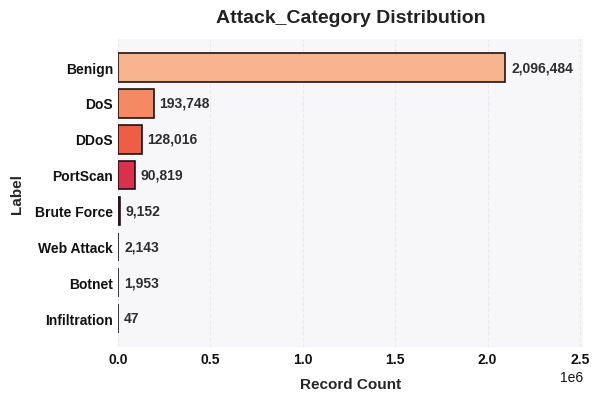

In [ ]:
label_counts = DATA["Attack_Category"].value_counts().sort_values(ascending=False)
categories = label_counts.index.astype(str)
values = label_counts.values
cmap = plt.get_cmap("rocket_r")
colors = cmap(np.linspace(0.15, 0.85, len(values)))
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(6, 4))
ax.set_facecolor("#f7f6f9")
bars = ax.barh(
    categories,
    values,
    color=colors,
    edgecolor="black",
    linewidth=1.2
)
ax.invert_yaxis()
for bar, val in zip(bars, values):
    ax.text(
        val + max(values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color="#2e2e2e")
ax.set_title(
    "Attack_Category Distribution",
    fontsize=14,
    fontweight="bold",
    pad=12,
    color="#222222")
ax.set_xlabel("Record Count", fontsize=11, fontweight="bold", labelpad=8)
ax.set_ylabel("Label", fontsize=11, fontweight="bold", labelpad=8)
ax.tick_params(axis="x", labelsize=10, colors="#111111", width=1.2)
ax.tick_params(axis="y", labelsize=10, colors="#111111", width=1.2)
for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.yaxis.grid(False)
sns.despine(left=True, bottom=True)
for patch in bars:
    patch.set_linewidth(1.2)
    patch.set_edgecolor("#111111")
    patch.set_alpha(0.97)
ax.set_xlim(0, max(values) * 1.20)
plt.show()

In [ ]:
numerical_cols = DATA.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()
print(numerical_cols)
print("Total Numerical Columns:", len(numerical_cols))

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [ ]:
categorical_cols = DATA.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()
print(categorical_cols)
print("Total Categorical Columns:", len(categorical_cols))

['Label', 'Attack_Category']
Total Categorical Columns: 2


In [ ]:
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    non_missing = DATA[col].notna()
    DATA.loc[non_missing, col] = le.fit_transform(
        DATA.loc[non_missing, col].astype(str)
    )
    DATA[col] = pd.to_numeric(DATA[col], errors="coerce")
    label_encoders[col] = le
    print(f"\n{col} Encoding Mapping:")
    print({
        category: int(index)
        for index, category in enumerate(le.classes_)
    })
DATA.head()


Label Encoding Mapping:
{'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS GoldenEye': 3, 'DoS Hulk': 4, 'DoS Slowhttptest': 5, 'DoS slowloris': 6, 'FTP-Patator': 7, 'Heartbleed': 8, 'Infiltration': 9, 'PortScan': 10, 'SSH-Patator': 11, 'Web Attack - Brute Force': 12, 'Web Attack - SQL Injection': 13, 'Web Attack - XSS': 14}

Attack_Category Encoding Mapping:
{'Benign': 0, 'Botnet': 1, 'Brute Force': 2, 'DDoS': 3, 'DoS': 4, 'Infiltration': 5, 'PortScan': 6, 'Web Attack': 7}


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_Category
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,0
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,0
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,0
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,0
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,0


In [ ]:
DATA = DATA.drop(columns=["Label"])

In [ ]:
DATA.columns

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Co

In [ ]:
X = DATA.drop(columns=["Attack_Category"]).select_dtypes(include="number")
X = X.replace([float("inf"), -float("inf")], float("nan"))
y = DATA.loc[X.index, "Attack_Category"]
valid_rows = X.notna().any(axis=1)
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)
if X.empty or y.nunique() < 2:
    raise ValueError("Insufficient valid features or classes.")
class_counts = y.value_counts()
if (class_counts < 2).any():
    raise ValueError(f"Each class needs at least 2 samples:\n{class_counts[class_counts < 2]}")
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.20, random_state=42, stratify=y_dev)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (1412522, 78)
Validation: (353131, 78)
Test: (756709, 78)


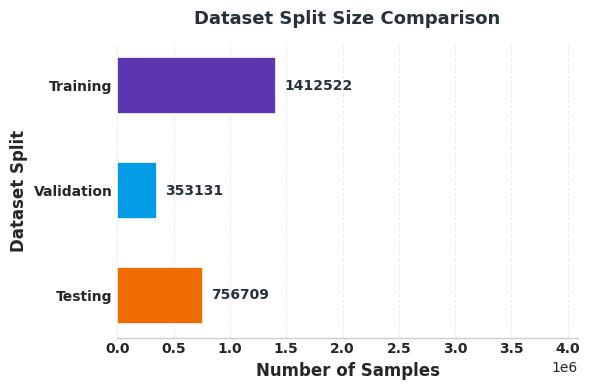

In [ ]:
sns.set_style("whitegrid")
split_sizes = pd.Series({"Training": len(X_train), "Validation": len(X_val), "Testing": len(X_test)})
fig, ax = plt.subplots(figsize=(6, 4))
bar_colors = ["#5E35B1", "#039BE5", "#EF6C00"]
bars = ax.barh(split_sizes.index, split_sizes.values, color=bar_colors, edgecolor="white", linewidth=1.2, height=0.55)
ax.bar_label(bars, fmt="%d", padding=6, fontsize=10, fontweight="bold", color="#263238")
ax.set_title("Dataset Split Size Comparison", fontsize=13, fontweight="bold", pad=14, color="#263238")
ax.set_xlabel("Number of Samples", fontsize=12, fontweight="bold")
ax.set_ylabel("Dataset Split", fontsize=12, fontweight="bold")
plt.setp(ax.get_xticklabels(), fontsize=10, fontweight="bold")
plt.setp(ax.get_yticklabels(), fontsize=10, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(values) * 1.95)
ax.invert_yaxis()
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

In [ ]:
print("\nCLASS COUNTS ")
print(pd.DataFrame({"Overall": y.value_counts(), "Train": y_train.value_counts(),
                    "Validation": y_val.value_counts(),
                    "Test": y_test.value_counts()}).fillna(0).astype(int))


CLASS COUNTS 
                 Overall    Train  Validation    Test
Attack_Category                                      
0                2096484  1174031      293508  628945
4                 193748   108499       27125   58124
3                 128016    71689       17922   38405
6                  90819    50858       12715   27246
2                   9152     5125        1281    2746
7                   2143     1200         300     643
1                   1953     1094         273     586
5                     47       26           7      14


In [1]:
POPULATION = 20
ITERATIONS = 40
ALPHA = 0.01
SEED = 42
OUTPUT_DIR = "MAO_Feature_Selection_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
start_time = time.time()
rng = np.random.default_rng(SEED)

feature_names = X_train.columns.astype(str).tolist() if isinstance(X_train, pd.DataFrame) else [f"Feature_{i+1}" for i in range(np.asarray(X_train).shape[1])]
X_tr = np.asarray(X_train, dtype=np.float32).copy()
X_va = np.asarray(X_val, dtype=np.float32).copy()
X_te = np.asarray(X_test, dtype=np.float32).copy()
y_tr = np.asarray(y_train).ravel()
y_va = np.asarray(y_val).ravel()
y_te = np.asarray(y_test).ravel()
n_features = X_tr.shape[1]

if X_tr.ndim != 2 or X_va.ndim != 2 or X_te.ndim != 2:
    raise ValueError("Train, validation and test must be 2D arrays.")
if X_va.shape[1] != n_features or X_te.shape[1] != n_features:
    raise ValueError("Train, validation and test feature counts differ.")
if len(feature_names) != n_features:
    raise ValueError("Feature names count does not match X_train.")
if len(y_tr) != len(X_tr) or len(y_va) != len(X_va) or len(y_te) != len(X_te):
    raise ValueError("Input data and label counts do not match.")
if n_features == 0:
    raise ValueError("No input features were found.")

print("MAO FEATURE SELECTION - INPUT DETAILS")
print("Training Shape:", X_tr.shape)
print("Validation Shape:", X_va.shape)
print("Testing Shape:", X_te.shape)
print("Original Feature Count:", n_features)
print("Number of Classes:", len(np.unique(y_tr)))

X_tr[~np.isfinite(X_tr)] = np.nan
X_va[~np.isfinite(X_va)] = np.nan
X_te[~np.isfinite(X_te)] = np.nan
train_medians = np.zeros(n_features, dtype=np.float32)

for j in range(n_features):
    valid_values = X_tr[np.isfinite(X_tr[:, j]), j]
    if len(valid_values) > 0:
        train_medians[j] = np.median(valid_values)
    X_tr[np.isnan(X_tr[:, j]), j] = train_medians[j]
    X_va[np.isnan(X_va[:, j]), j] = train_medians[j]
    X_te[np.isnan(X_te[:, j]), j] = train_medians[j]

fitness_cache = {}

def evaluate_fitness(mask):
    mask = np.asarray(mask, dtype=bool)
    selected_count = int(mask.sum())
    if selected_count == 0:
        return float("inf")
    key = mask.tobytes()
    if key not in fitness_cache:
        model = RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1)
        model.fit(X_tr[:, mask], y_tr)
        val_pred = model.predict(X_va[:, mask])
        val_accuracy = accuracy_score(y_va, val_pred)
        validation_error = 1.0 - val_accuracy
        feature_penalty = ALPHA * (selected_count / n_features)
        fitness_cache[key] = float(validation_error + feature_penalty)
    return fitness_cache[key]

print("MAO INITIALIZATION")
population = rng.integers(0, 2, size=(POPULATION, n_features)).astype(bool)
for i in range(POPULATION):
    if not population[i].any():
        population[i, rng.integers(0, n_features)] = True
fitness_values = np.array([evaluate_fitness(individual) for individual in population])
best_index = int(np.argmin(fitness_values))
best_mask = population[best_index].copy()
best_fitness = float(fitness_values[best_index])
convergence_curve = [best_fitness]
print("Population Size:", POPULATION)
print("Number of Iterations:", ITERATIONS)
print("Original Features:", n_features)
print("Initial Best Fitness:", f"{best_fitness:.8f}")
print("Initial Selected Features:", int(best_mask.sum()))

print("MAO OPTIMIZATION")

for iteration in range(ITERATIONS):
    new_population = population.copy()
    exploration_rate = 1.0 - iteration / max(ITERATIONS, 1)
    exploitation_rate = 0.20 + 0.60 * iteration / max(ITERATIONS - 1, 1)
    for i in range(POPULATION):
        candidate = population[i].copy()
        flip_count = max(1, int(exploration_rate * n_features * 0.10))
        flip_count = min(flip_count, n_features)
        flip_indices = rng.choice(n_features, size=flip_count, replace=False)
        candidate[flip_indices] = ~candidate[flip_indices]
        follow_mask = rng.random(n_features) < exploitation_rate
        candidate[follow_mask] = best_mask[follow_mask]
        if not candidate.any():
            candidate[rng.integers(0, n_features)] = True
        new_population[i] = candidate
    new_fitness_values = np.array([evaluate_fitness(individual) for individual in new_population])
    for i in range(POPULATION):
        if new_fitness_values[i] <= fitness_values[i]:
            population[i] = new_population[i].copy()
            fitness_values[i] = new_fitness_values[i]
    current_best_index = int(np.argmin(fitness_values))
    current_best_fitness = float(fitness_values[current_best_index])
    if current_best_fitness < best_fitness:
        best_fitness = current_best_fitness
        best_mask = population[current_best_index].copy()
    best_fitness = min(best_fitness, convergence_curve[-1])
    convergence_curve.append(best_fitness)
    print(f"Iteration {iteration + 1:02d}/{ITERATIONS} | Best Fitness: {best_fitness:.8f} | Selected Features: {int(best_mask.sum())} | Exploration: {exploration_rate:.3f} | Exploitation: {exploitation_rate:.3f}")

selected_mask = best_mask.copy()
selected_indices = np.flatnonzero(selected_mask)
selected_features = [feature_names[i] for i in selected_indices]
X_train_MAO = X_tr[:, selected_indices].copy()
X_val_MAO = X_va[:, selected_indices].copy()
X_test_MAO = X_te[:, selected_indices].copy()

fitness_differences = np.diff(convergence_curve)
is_monotonic = bool(np.all(fitness_differences <= 1e-12))
assert is_monotonic, "ERROR: Best-so-far fitness increased!"

execution_time = time.time() - start_time

MAO FEATURE SELECTION - INPUT DETAILS
Training Shape: (1412522, 78)
Validation Shape: (353131, 78)
Testing Shape: (756709, 78)
Original Feature Count: 78
Number of Classes: 8
MAO INITIALIZATION
Population Size: 20
Number of Iterations: 40
Original Features: 78
Initial Best Fitness: 0.00692280
Initial Selected Features: 39
MAO OPTIMIZATION
Iteration 01/40 | Best Fitness: 0.00692280 | Selected Features: 39 | Exploration: 1.000 | Exploitation: 0.200
Iteration 02/40 | Best Fitness: 0.00672612 | Selected Features: 41 | Exploration: 0.975 | Exploitation: 0.215
Iteration 03/40 | Best Fitness: 0.00572442 | Selected Features: 31 | Exploration: 0.950 | Exploitation: 0.231
Iteration 04/40 | Best Fitness: 0.00572442 | Selected Features: 31 | Exploration: 0.925 | Exploitation: 0.246
Iteration 05/40 | Best Fitness: 0.00569533 | Selected Features: 30 | Exploration: 0.900 | Exploitation: 0.262
Iteration 06/40 | Best Fitness: 0.00569533 | Selected Features: 30 | Exploration: 0.875 | Exploitation: 0.277

In [3]:

print("MAO SELECTED FEATURE NAMES")
print(f"Total Selected Features: {len(selected_features)}\n")
for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")


MAO SELECTED FEATURES
Total Selected Features: 19



,S.No,Selected_Feature
0,1,Total Length of Bwd Packets
1,2,Fwd Packet Length Mean
2,3,Bwd Packet Length Min
3,4,Bwd Packet Length Std
4,5,Fwd IAT Total
5,6,Fwd IAT Min
6,7,Bwd URG Flags
7,8,Fwd Header Length
8,9,Fwd Packets/s
9,10,Packet Length Std


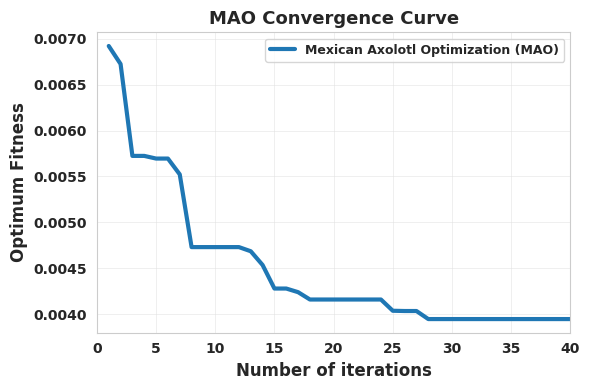

Total Iterations       : 40
Initial Best Fitness   : 0.00692280
Final Best Fitness     : 0.00394525
Final Selected Features: 19


In [2]:
plt.figure(figsize=(6, 4))
plt.plot(range(len(convergence_curve)),convergence_curve,linewidth=3,label="Mexican Axolotl Optimization (MAO)",)
plt.xlabel("Number of iterations", fontsize=12, fontweight="bold")
plt.ylabel("Optimum Fitness", fontsize=12, fontweight="bold")
plt.title("MAO Convergence Curve", fontsize=13, fontweight="bold")

plt.xticks(fontweight="bold")
plt.yticks(fontweight="bold")
plt.grid(True, linestyle="-", linewidth=0.5, color="#e0e0e0", alpha=0.7)
plt.legend(loc="upper right", frameon=True,
           prop={"weight": "bold", "size": 10})
plt.tight_layout()
plt.show()
plt.close()

print("Total Iterations       :", len(convergence_curve))
print("Initial Best Fitness   :", f"{convergence_curve[0]:.8f}")
print("Final Best Fitness     :", f"{convergence_curve[-1]:.8f}")
print("Final Selected Features: 19")


In [5]:
print("FEATURE SELECTION SUMMARY")
print(f"Original Feature Count : {n_features}")
print(f"Selected Feature Count : {len(selected_features)}")
print(f"Removed Feature Count  : {n_features - len(selected_features)}")
print(f"Best Fitness           : {best_fitness:.8f}")
print(f"Execution Time         : {execution_time:.2f} seconds")
print(f"Train shape      : {X_train_MAO.shape}")
print(f"Validation shape : {X_val_MAO.shape}")
print(f"Test shape       : {X_test_MAO.shape}")

FEATURE SELECTION SUMMARY
Original Feature Count : 78
Selected Feature Count : 19
Removed Feature Count  : 59
Best Fitness           : 0.00394525
Execution Time         : 1070.23 seconds
Train shape      : (1412522, 19)
Validation shape : (353131, 19)
Test shape       : (756709, 19)


In [6]:
if isinstance(X_train, pd.DataFrame):
    X_train_df = X_train.copy()
    X_val_df = X_val.copy() if isinstance(X_val, pd.DataFrame) else pd.DataFrame(X_val, columns=X_train.columns)
    X_test_df = X_test.copy() if isinstance(X_test, pd.DataFrame) else pd.DataFrame(X_test, columns=X_train.columns)
else:
    X_train_df = pd.DataFrame(X_train)
    X_val_df = pd.DataFrame(X_val)
    X_test_df = pd.DataFrame(X_test)

if not (X_train_df.shape[1] == X_val_df.shape[1] == X_test_df.shape[1]):
    raise ValueError("Train, validation and test feature counts differ.")

train_mean = X_train_df.mean()
train_std = X_train_df.std(ddof=0).replace(0, 1).fillna(1)

X_train = ((X_train_df - train_mean) / train_std).to_numpy(dtype=np.float32)
X_val = ((X_val_df - train_mean) / train_std).to_numpy(dtype=np.float32)
X_test = ((X_test_df - train_mean) / train_std).to_numpy(dtype=np.float32)

print("Z-score normalization completed successfully.")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Z-score normalization completed.
Selected features: 19
Train shape: (1412522, 19)
Validation shape: (353131, 19)
Test shape: (756709, 19)
Data type: float32


In [ ]:
SEEDS=[42,56,67,123,245]
BATCH_SIZE=64
EPOCHS=10
PATIENCE=8
LEARNING_RATE=0.0001
WEIGHT_DECAY=1e-4
D_MODEL=64
NUM_HEADS=4
NUM_TRANSFORMER_LAYERS=2
GRU_HIDDEN=64
DROPOUT=0.30
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
required_variables=["X_train_MAO","X_val_MAO","X_test_MAO","y_train","y_val","y_test"]
missing_variables=[v for v in required_variables if v not in globals()]
if missing_variables: raise NameError("Run the MAO feature-selection cell first. Missing: "+", ".join(missing_variables))
def convert_features_to_numpy(data):
    if isinstance(data,(pd.DataFrame,pd.Series)): data=data.to_numpy()
    data=np.asarray(data,dtype=np.float32)
    if data.ndim==1: data=data.reshape(-1,1)
    if data.ndim!=2: raise ValueError(f"Expected 2D features, received {data.shape}")
    return np.nan_to_num(data,nan=0.0,posinf=0.0,neginf=0.0)
X_train_np=convert_features_to_numpy(X_train_MAO)
X_val_np=convert_features_to_numpy(X_val_MAO)
X_test_np=convert_features_to_numpy(X_test_MAO)
y_train_raw=np.asarray(y_train).reshape(-1)
y_val_raw=np.asarray(y_val).reshape(-1)
y_test_raw=np.asarray(y_test).reshape(-1)
if not(len(X_train_np)==len(y_train_raw) and len(X_val_np)==len(y_val_raw) and len(X_test_np)==len(y_test_raw)): raise ValueError("Feature and label sample counts do not match.")
if not(X_train_np.shape[1]==X_val_np.shape[1]==X_test_np.shape[1]): raise ValueError("Feature counts do not match.")
INPUT_DIM=X_train_np.shape[1]
label_encoder=LabelEncoder()
label_encoder.fit(np.concatenate([y_train_raw,y_val_raw,y_test_raw]))
y_train_encoded=label_encoder.transform(y_train_raw)
y_val_encoded=label_encoder.transform(y_val_raw)
y_test_encoded=label_encoder.transform(y_test_raw)
class_names=label_encoder.classes_.astype(str).tolist()
NUM_CLASSES=len(class_names)
train_class_counts=np.bincount(y_train_encoded,minlength=NUM_CLASSES)
present_classes=np.unique(y_train_encoded)
class_weights_np=np.ones(NUM_CLASSES,dtype=np.float32)
class_weights_np[present_classes]=compute_class_weight(class_weight="balanced",classes=present_classes,y=y_train_encoded)
class_weights=torch.tensor(class_weights_np,dtype=torch.float32,device=DEVICE)
X_train_tensor=torch.tensor(X_train_np,dtype=torch.float32)
X_val_tensor=torch.tensor(X_val_np,dtype=torch.float32)
X_test_tensor=torch.tensor(X_test_np,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train_encoded,dtype=torch.long)
y_val_tensor=torch.tensor(y_val_encoded,dtype=torch.long)
y_test_tensor=torch.tensor(y_test_encoded,dtype=torch.long)
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
val_dataset=TensorDataset(X_val_tensor,y_val_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

print("HYBRIDQBiDR_NALT - CLASS-WEIGHTED TRAINING")
print("Device:",DEVICE)
print("Seeds:",SEEDS)
print("Train:",X_train_np.shape,"Validation:",X_val_np.shape,"Test:",X_test_np.shape)
print("Input Features:",INPUT_DIM,"Number of Classes:",NUM_CLASSES)
print("Class Names:",class_names)
print("\nTraining Class Counts and Weights")
for i,name in enumerate(class_names): print(f"{name}: Count={train_class_counts[i]}, Weight={class_weights_np[i]:.6f}")

HYBRIDQBiDR_NALT - CLASS-WEIGHTED TRAINING
Device: cuda
Seeds: [42, 56, 67, 123, 245]
Train: (1412522, 19) Validation: (353131, 19) Test: (756709, 19)
Input Features: 19 Number of Classes: 8
Class Names: ['0', '1', '2', '3', '4', '5', '6', '7']

Training Class Counts and Weights
0: Count=1174031, Weight=0.150392
1: Count=1094, Weight=161.394196
2: Count=5125, Weight=34.451756
3: Count=71689, Weight=2.462934
4: Count=108499, Weight=1.627344
5: Count=26, Weight=6790.971191
6: Count=50858, Weight=3.471730
7: Count=1200, Weight=147.137711


In [ ]:
class NALUInspiredBlock(nn.Module):
    def __init__(self,input_dim,output_dim):
        super().__init__()
        self.W_hat=nn.Parameter(torch.empty(input_dim,output_dim))
        self.M_hat=nn.Parameter(torch.empty(input_dim,output_dim))
        self.G=nn.Linear(input_dim,output_dim)
        nn.init.xavier_uniform_(self.W_hat)
        nn.init.xavier_uniform_(self.M_hat)
    def forward(self,x):
        W=torch.tanh(self.W_hat)*torch.sigmoid(self.M_hat)
        additive=torch.matmul(x,W)
        multiplicative=torch.exp(torch.matmul(torch.log(torch.abs(x)+1e-7),W))
        multiplicative=torch.nan_to_num(multiplicative,nan=0.0,posinf=1e4,neginf=0.0).clamp(-1e4,1e4)
        gate=torch.sigmoid(self.G(x))
        return torch.nan_to_num(gate*additive+(1-gate)*multiplicative,nan=0.0,posinf=1e4,neginf=-1e4)
class QuantumInspiredBranch(nn.Module):
    def __init__(self,input_dim,output_dim,dropout=0.3):
        super().__init__()
        self.projection=nn.Linear(input_dim,output_dim)
        self.phase_projection=nn.Linear(input_dim,output_dim)
        self.fusion=nn.Sequential(nn.Linear(output_dim*2,output_dim),nn.GELU(),nn.Dropout(dropout),nn.LayerNorm(output_dim))
    def forward(self,x):
        return self.fusion(torch.cat([torch.sin(self.projection(x)),torch.cos(self.phase_projection(x))],dim=1))
class HYBRIDQBiDR_NALT(nn.Module):
    def __init__(self,input_dim,num_classes,d_model=64,num_heads=4,num_transformer_layers=2,gru_hidden=64,dropout=0.30):
        super().__init__()
        self.feature_embedding=nn.Linear(1,d_model)
        self.position_embedding=nn.Parameter(torch.randn(1,input_dim,d_model)*0.02)
        layer=nn.TransformerEncoderLayer(d_model=d_model,nhead=num_heads,dim_feedforward=d_model*2,dropout=dropout,activation="gelu",batch_first=True,norm_first=True)
        self.transformer=nn.TransformerEncoder(layer,num_layers=num_transformer_layers)
        self.transformer_norm=nn.LayerNorm(d_model)
        self.quantum_branch=QuantumInspiredBranch(input_dim,d_model,dropout)
        self.gru_input_projection=nn.Linear(1,d_model)
        self.bigru=nn.GRU(d_model,gru_hidden,batch_first=True,bidirectional=True)
        self.gru_norm=nn.LayerNorm(gru_hidden*2)
        self.gru_projection=nn.Sequential(nn.Linear(gru_hidden*2,d_model),nn.GELU(),nn.Dropout(dropout))
        self.nalu_branch=nn.Sequential(NALUInspiredBlock(input_dim,d_model),nn.LayerNorm(d_model),nn.GELU(),nn.Dropout(dropout))
        self.fusion=nn.Sequential(nn.Linear(d_model*4,d_model*2),nn.LayerNorm(d_model*2),nn.GELU(),nn.Dropout(dropout),nn.Linear(d_model*2,d_model),nn.LayerNorm(d_model),nn.GELU(),nn.Dropout(dropout))
        self.classifier=nn.Linear(d_model,num_classes)
    def forward(self,x):
        t=self.transformer_norm(self.transformer(self.feature_embedding(x.unsqueeze(-1))+self.position_embedding)).mean(dim=1)
        q=self.quantum_branch(x)
        g,_=self.bigru(self.gru_input_projection(x.unsqueeze(-1)))
        g=self.gru_projection(self.gru_norm(g).mean(dim=1))
        n=self.nalu_branch(x)
        return self.classifier(self.fusion(torch.cat([t,q,g,n],dim=1)))
def evaluate_model(model,data_loader,criterion):
    model.eval()
    total_loss=0.0
    total_samples=0
    labels,predictions,probabilities=[],[],[]
    with torch.no_grad():
        for bx,by in data_loader:
            bx,by=bx.to(DEVICE),by.to(DEVICE)
            logits=model(bx)
            loss=criterion(logits,by)
            probs=torch.softmax(logits,dim=1)
            total_loss+=loss.item()*by.size(0)
            total_samples+=by.size(0)
            labels.extend(by.cpu().numpy())
            predictions.extend(probs.argmax(dim=1).cpu().numpy())
            probabilities.extend(probs.cpu().numpy())
    yt=np.asarray(labels)
    yp=np.asarray(predictions)
    yp_prob=np.asarray(probabilities)
    metrics={"Loss":total_loss/max(total_samples,1),"Accuracy":accuracy_score(yt,yp),"Precision_Macro":precision_score(yt,yp,average="macro",zero_division=0),"Recall_Macro":recall_score(yt,yp,average="macro",zero_division=0),"F1_Macro":f1_score(yt,yp,average="macro",zero_division=0),"Precision_Weighted":precision_score(yt,yp,average="weighted",zero_division=0),"Recall_Weighted":recall_score(yt,yp,average="weighted",zero_division=0),"F1_Weighted":f1_score(yt,yp,average="weighted",zero_division=0)}
    try:
        if NUM_CLASSES==2:
            metrics["ROC_AUC"]=roc_auc_score(yt,yp_prob[:,1])
            metrics["Average_Precision"]=average_precision_score(yt,yp_prob[:,1])
        else:
            ybin=label_binarize(yt,classes=np.arange(NUM_CLASSES))
            metrics["ROC_AUC"]=roc_auc_score(ybin,yp_prob,average="macro",multi_class="ovr")
            metrics["Average_Precision"]=average_precision_score(ybin,yp_prob,average="macro")
    except (ValueError,IndexError): metrics["ROC_AUC"]=np.nan; metrics["Average_Precision"]=np.nan
    return metrics,yt,yp,yp_prob

In [ ]:
all_results=[]
seed_outputs={}
overall_start_time=time.time()
for seed in SEEDS:
    print(f"TRAINING SEED: {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    generator=torch.Generator().manual_seed(seed)
    train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,generator=generator,num_workers=0)
    val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    model=HYBRIDQBiDR_NALT(INPUT_DIM,NUM_CLASSES,D_MODEL,NUM_HEADS,NUM_TRANSFORMER_LAYERS,GRU_HIDDEN,DROPOUT).to(DEVICE)
    criterion=nn.CrossEntropyLoss(weight=class_weights)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="min",factor=0.5,patience=2)
    history={"train_loss":[],"val_loss":[],"train_accuracy":[],"val_accuracy":[],"learning_rate":[]}
    best_val_loss=float("inf")
    best_epoch=0
    best_state=None
    patience_counter=0
    start_time=time.time()
    for epoch in range(EPOCHS):
        model.train()
        running_loss=0.0
        running_correct=0
        running_samples=0
        for bx,by in train_loader:
            bx,by=bx.to(DEVICE),by.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits=model(bx)
            loss=criterion(logits,by)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
            optimizer.step()
            n=by.size(0)
            running_loss+=loss.item()*n
            running_correct+=(logits.detach().argmax(dim=1)==by).sum().item()
            running_samples+=n
        train_loss=running_loss/max(running_samples,1)
        train_accuracy=running_correct/max(running_samples,1)
        val_metrics,_,_,_=evaluate_model(model,val_loader,criterion)
        val_loss=val_metrics["Loss"]
        val_accuracy=val_metrics["Accuracy"]
        scheduler.step(val_loss)
        lr=optimizer.param_groups[0]["lr"]
        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        history["train_accuracy"].append(float(train_accuracy))
        history["val_accuracy"].append(float(val_accuracy))
        history["learning_rate"].append(float(lr))
        print(f"Seed {seed} | Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f} | Train Acc: {train_accuracy:.4f} | Val Acc: {val_accuracy:.4f} | LR: {lr:.7f}")
        if val_loss<best_val_loss:
            best_val_loss=val_loss
            best_epoch=epoch+1
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            patience_counter=0
        else:
            patience_counter+=1
        if patience_counter>=PATIENCE:
            print(f"Early stopping at epoch {epoch+1} for seed {seed}")
            break
    training_time=time.time()-start_time
    model.load_state_dict(best_state)
    val_metrics,val_true,val_pred,val_prob=evaluate_model(model,val_loader,criterion)
    test_metrics,test_true,test_pred,test_prob=evaluate_model(model,test_loader,criterion)
    seed_outputs[seed]={"model_state":best_state,"history":history,"best_epoch":best_epoch,"best_val_loss":best_val_loss,"training_time":training_time,"validation_metrics":val_metrics,"validation_true":val_true,"validation_pred":val_pred,"validation_prob":val_prob,"test_metrics":test_metrics,"test_true":test_true,"test_pred":test_pred,"test_prob":test_prob}
    result={"Seed":seed,"Best_Epoch":best_epoch,"Training_Time_Seconds":training_time,"Best_Validation_Loss":best_val_loss}
    result.update({f"Test_{k}":v for k,v in test_metrics.items()})
    result.update({f"Validation_{k}":v for k,v in val_metrics.items()})
    all_results.append(result)
    print(f"\nSeed {seed} completed | Best Epoch: {best_epoch} | Training Time: {training_time:.2f}s")
    print("Test Metrics:")
    for k,v in test_metrics.items(): print(f"{k}: {v:.6f}")
overall_training_time=time.time()-overall_start_time
results_df=pd.DataFrame(all_results)
print("ALL FIVE SEEDS TRAINING COMPLETED")
print(f"Total Training Time: {overall_training_time:.2f} seconds")
display(results_df)

TRAINING SEED: 42
Seed 42 | Epoch 01/10 | Train Loss: 0.528019 | Val Loss: 0.336545 | Train Acc: 0.9213 | Val Acc: 0.9609 | LR: 0.0001000
Seed 42 | Epoch 02/10 | Train Loss: 0.348301 | Val Loss: 0.282582 | Train Acc: 0.9576 | Val Acc: 0.9650 | LR: 0.0001000
Seed 42 | Epoch 03/10 | Train Loss: 0.320063 | Val Loss: 0.284795 | Train Acc: 0.9627 | Val Acc: 0.9666 | LR: 0.0001000
Seed 42 | Epoch 04/10 | Train Loss: 0.283936 | Val Loss: 0.190903 | Train Acc: 0.9665 | Val Acc: 0.9674 | LR: 0.0001000
Seed 42 | Epoch 05/10 | Train Loss: 0.262427 | Val Loss: 0.197126 | Train Acc: 0.9717 | Val Acc: 0.9743 | LR: 0.0001000
Seed 42 | Epoch 06/10 | Train Loss: 0.255205 | Val Loss: 0.198964 | Train Acc: 0.9748 | Val Acc: 0.9773 | LR: 0.0001000
Seed 42 | Epoch 07/10 | Train Loss: 0.251385 | Val Loss: 0.180838 | Train Acc: 0.9773 | Val Acc: 0.9770 | LR: 0.0001000
Seed 42 | Epoch 08/10 | Train Loss: 0.243448 | Val Loss: 0.203595 | Train Acc: 0.9785 | Val Acc: 0.9867 | LR: 0.0001000
Seed 42 | Epoch 09/10 

,Seed,Best_Epoch,Training_Time_Seconds,Best_Validation_Loss,Test_Loss,Test_Accuracy,Test_Precision_Macro,Test_Recall_Macro,Test_F1_Macro,Test_Precision_Weighted,...,Validation_Loss,Validation_Accuracy,Validation_Precision_Macro,Validation_Recall_Macro,Validation_F1_Macro,Validation_Precision_Weighted,Validation_Recall_Weighted,Validation_F1_Weighted,Validation_ROC_AUC,Validation_Average_Precision
0,42,9,3074.656358,0.154652,0.144364,0.976157,0.727266,0.852232,0.746807,0.981444,...,0.154652,0.975618,0.638264,0.797877,0.677371,0.981192,0.975618,0.977828,0.990757,0.759849
1,56,7,3063.166826,0.148264,0.141511,0.979131,0.667764,0.808887,0.701021,0.983252,...,0.148264,0.979192,0.713298,0.816593,0.714975,0.983422,0.979192,0.980859,0.987408,0.800689
2,67,10,3117.277696,0.162328,0.155157,0.985642,0.793049,0.836284,0.755357,0.988904,...,0.162328,0.985300,0.664529,0.800298,0.697126,0.988679,0.985300,0.986728,0.991778,0.783132
3,123,9,3110.454161,0.193889,0.181574,0.987701,0.838406,0.735624,0.723680,0.988112,...,0.193889,0.987447,0.684209,0.689140,0.650897,0.987735,0.987447,0.987289,0.986770,0.795546
4,245,7,3141.803807,0.169012,0.162905,0.982097,0.783117,0.843163,0.754635,0.986768,...,0.169012,0.981726,0.651706,0.798264,0.683863,0.986687,0.981726,0.983825,0.988702,0.761241


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
from sklearn.metrics import classification_report
for seed in SEEDS:
    output=seed_outputs[seed]
    print(f"CLASSIFICATION REPORT - SEED {seed}")
    print(classification_report(output["test_true"],output["test_pred"],labels=np.arange(NUM_CLASSES),target_names=class_names,digits=4,zero_division=0))

CLASSIFICATION REPORT - SEED 42
              precision    recall  f1-score   support

           0     0.9946    0.9768    0.9856    628945
           1     0.3426    0.6075    0.4382       586
           2     0.9018    0.9629    0.9313      2746
           3     0.9947    0.9812    0.9879     38405
           4     0.9029    0.9639    0.9324     58124
           5     0.6667    0.4286    0.5217        14
           6     0.8694    0.9919    0.9266     27246
           7     0.1455    0.9051    0.2508       643

    accuracy                         0.9762    756709
   macro avg     0.7273    0.8522    0.7468    756709
weighted avg     0.9814    0.9762    0.9782    756709

CLASSIFICATION REPORT - SEED 56
              precision    recall  f1-score   support

           0     0.9945    0.9805    0.9874    628945
           1     0.3460    0.6075    0.4409       586
           2     0.9385    0.9618    0.9500      2746
           3     0.9123    0.9988    0.9536     38405
           4  

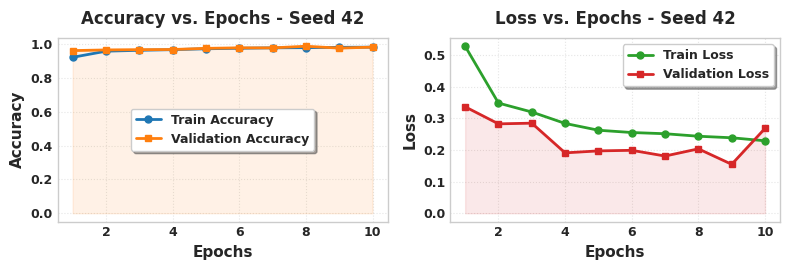

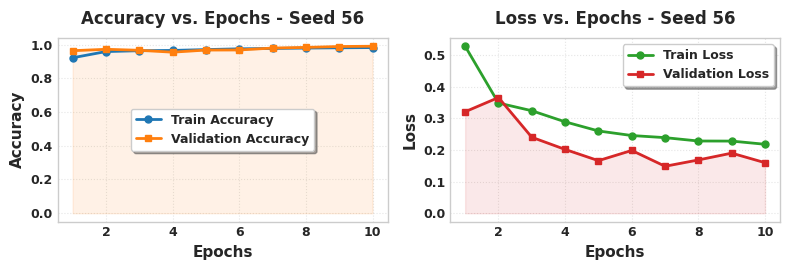

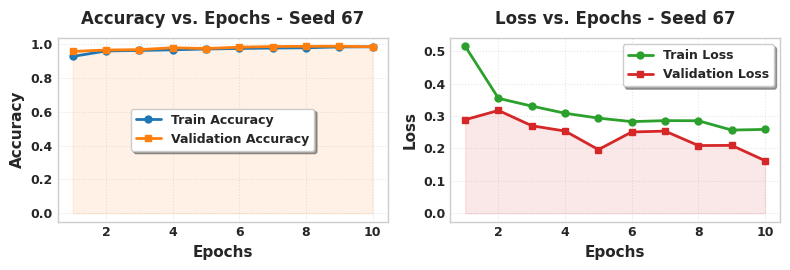

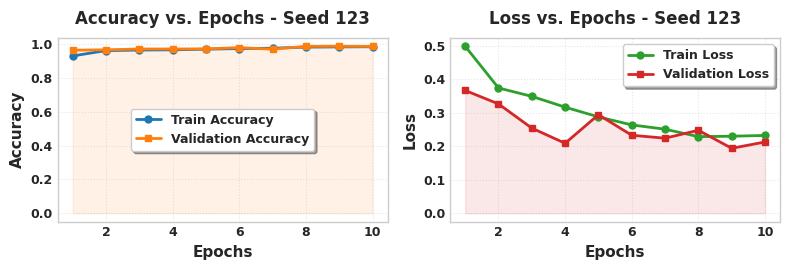

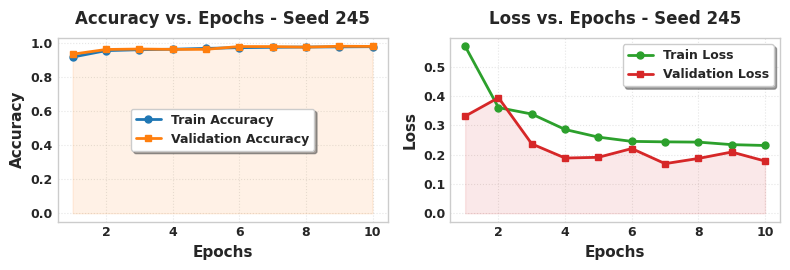

In [ ]:
for seed in SEEDS:
    history = seed_outputs[seed]["history"]
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 2.8))

    ax1.plot(epochs, history["train_accuracy"], color="#1f77b4", linestyle="-", marker="o", markersize=5, linewidth=2, label="Train Accuracy")
    ax1.plot(epochs, history["val_accuracy"], color="#ff7f0e", linestyle="-", marker="s", markersize=5, linewidth=2, label="Validation Accuracy")
    ax1.fill_between(epochs, history["val_accuracy"], color="#ff7f0e", alpha=0.1)
    ax1.set_xlabel("Epochs", fontsize=11, fontweight="bold")
    ax1.set_ylabel("Accuracy", fontsize=11, fontweight="bold")
    ax1.set_title(f"Accuracy vs. Epochs - Seed {seed}", fontsize=12, fontweight="bold", pad=10)
    ax1.tick_params(axis="both", labelsize=9)
    for tick in ax1.get_xticklabels() + ax1.get_yticklabels():
        tick.set_fontweight("bold")
    ax1.legend(frameon=True, shadow=True, prop={"weight": "bold", "size": 9})
    ax1.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

    ax2.plot(epochs, history["train_loss"], color="#2ca02c", linestyle="-", marker="o", markersize=5, linewidth=2, label="Train Loss")
    ax2.plot(epochs, history["val_loss"], color="#d62728", linestyle="-", marker="s", markersize=5, linewidth=2, label="Validation Loss")
    ax2.fill_between(epochs, history["val_loss"], color="#d62728", alpha=0.1)
    ax2.set_xlabel("Epochs", fontsize=11, fontweight="bold")
    ax2.set_ylabel("Loss", fontsize=11, fontweight="bold")
    ax2.set_title(f"Loss vs. Epochs - Seed {seed}", fontsize=12, fontweight="bold", pad=10)
    ax2.tick_params(axis="both", labelsize=9)
    for tick in ax2.get_xticklabels() + ax2.get_yticklabels():
        tick.set_fontweight("bold")
    ax2.legend(frameon=True, shadow=True, prop={"weight": "bold", "size": 9})
    ax2.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

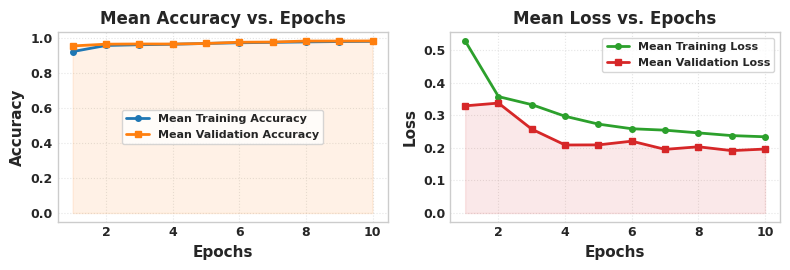

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

train_acc_all, val_acc_all, train_loss_all, val_loss_all = [], [], [], []

for seed in SEEDS:
    history = seed_outputs[seed]["history"]
    train_acc_all.append(history["train_accuracy"])
    val_acc_all.append(history["val_accuracy"])
    train_loss_all.append(history["train_loss"])
    val_loss_all.append(history["val_loss"])

train_acc_all = np.asarray(train_acc_all, dtype=float)
val_acc_all = np.asarray(val_acc_all, dtype=float)
train_loss_all = np.asarray(train_loss_all, dtype=float)
val_loss_all = np.asarray(val_loss_all, dtype=float)

mean_train_acc = np.mean(train_acc_all, axis=0)
mean_val_acc = np.mean(val_acc_all, axis=0)
mean_train_loss = np.mean(train_loss_all, axis=0)
mean_val_loss = np.mean(val_loss_all, axis=0)
epochs = np.arange(1, len(mean_train_acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 2.8))

ax1.plot(epochs, mean_train_acc, color="#1f77b4", linestyle="-", marker="o", markersize=4, linewidth=2, label="Mean Training Accuracy")
ax1.plot(epochs, mean_val_acc, color="#ff7f0e", linestyle="-", marker="s", markersize=4, linewidth=2, label="Mean Validation Accuracy")
ax1.fill_between(epochs, mean_val_acc, color="#ff7f0e", alpha=0.10)
ax1.set_xlabel("Epochs", fontsize=11, fontweight="bold")
ax1.set_ylabel("Accuracy", fontsize=11, fontweight="bold")
ax1.set_title("Mean Accuracy vs. Epochs", fontsize=12, fontweight="bold")
ax1.tick_params(axis="both", labelsize=9)
for tick in ax1.get_xticklabels() + ax1.get_yticklabels():
    tick.set_fontweight("bold")
ax1.legend(frameon=True, prop={"weight": "bold", "size": 8})
ax1.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

ax2.plot(epochs, mean_train_loss, color="#2ca02c", linestyle="-", marker="o", markersize=4, linewidth=2, label="Mean Training Loss")
ax2.plot(epochs, mean_val_loss, color="#d62728", linestyle="-", marker="s", markersize=4, linewidth=2, label="Mean Validation Loss")
ax2.fill_between(epochs, mean_val_loss, color="#d62728", alpha=0.10)
ax2.set_xlabel("Epochs", fontsize=11, fontweight="bold")
ax2.set_ylabel("Loss", fontsize=11, fontweight="bold")
ax2.set_title("Mean Loss vs. Epochs", fontsize=12, fontweight="bold")
ax2.tick_params(axis="both", labelsize=9)
for tick in ax2.get_xticklabels() + ax2.get_yticklabels():
    tick.set_fontweight("bold")
ax2.legend(frameon=True, prop={"weight": "bold", "size": 8})
ax2.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

plt.tight_layout()
plt.show()
plt.close(fig)


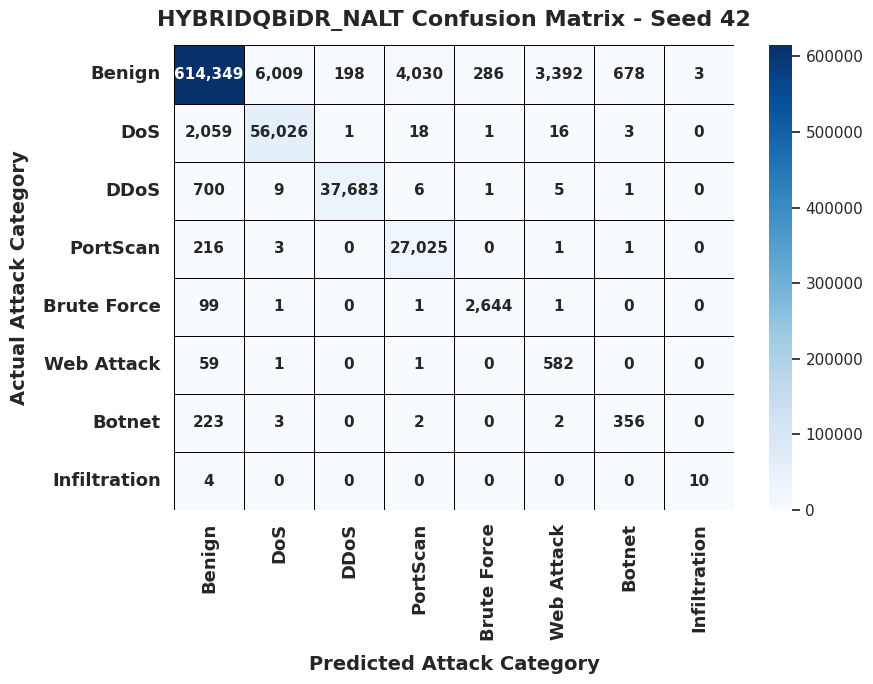

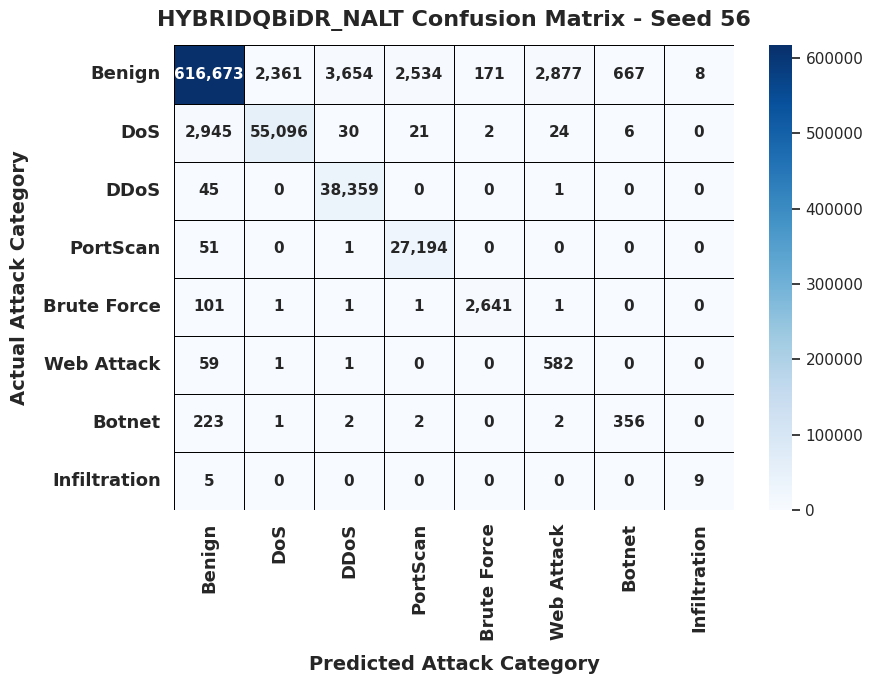

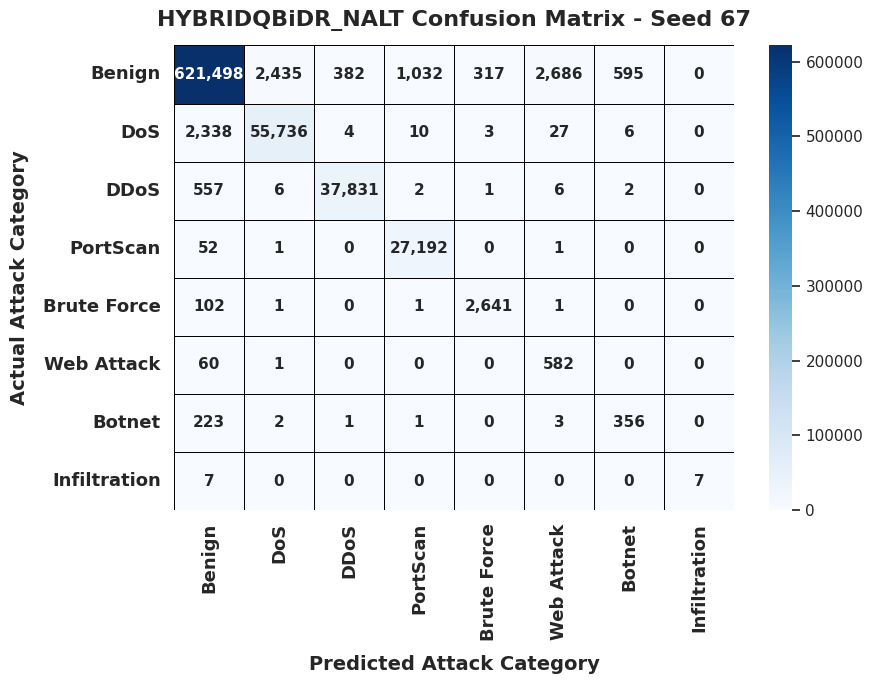

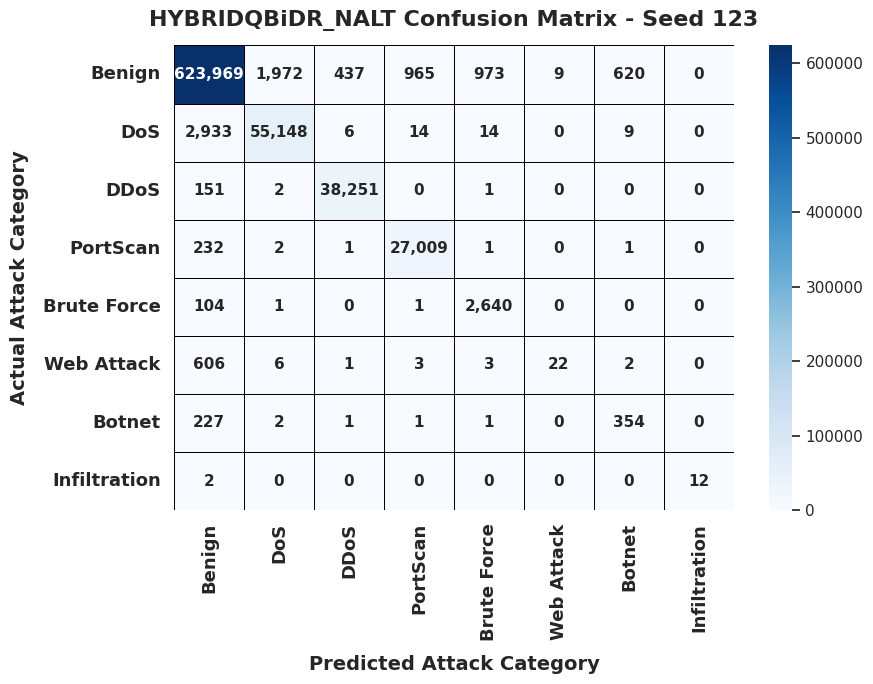

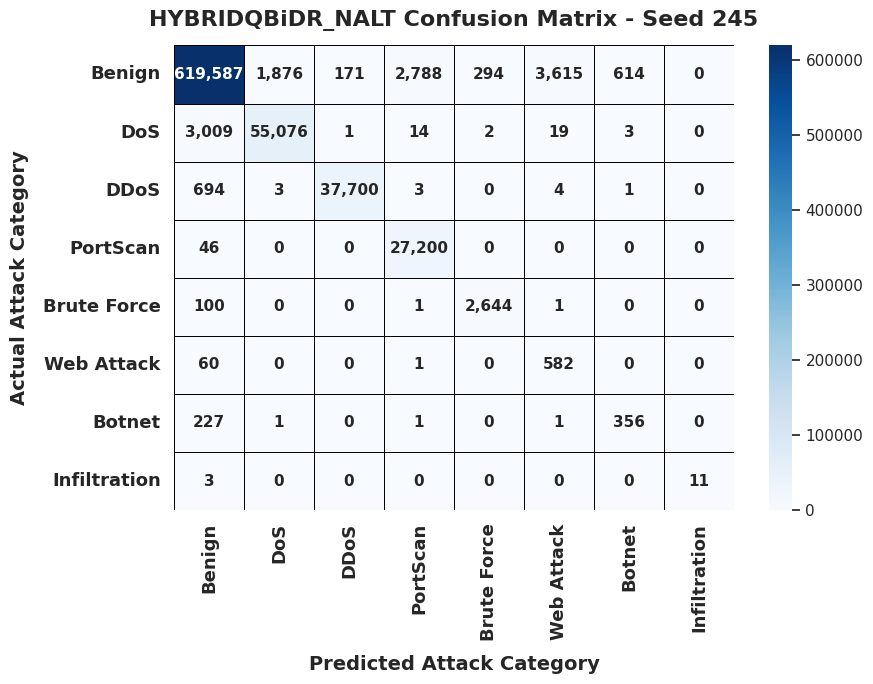

In [ ]:
attack_category_mapping = {
    'Benign': 0,
    'Botnet': 1,
    'Brute Force': 2,
    'DDoS': 3,
    'DoS': 4,
    'Infiltration': 5,
    'PortScan': 6,
    'Web Attack': 7}


class_names = [
    name for name, encoding in sorted(
        attack_category_mapping.items(),
        key=lambda item: item[1]
    )]

NUM_CLASSES = len(class_names)

for seed in SEEDS:
    output = seed_outputs[seed]

    cm_raw = confusion_matrix(
        output["test_true"],
        output["test_pred"],
        labels=np.arange(NUM_CLASSES)
    )

    class_totals = cm_raw.sum(axis=1) + cm_raw.sum(axis=0)
    sorted_indices = np.argsort(class_totals)[::-1]

    cm = cm_raw[np.ix_(sorted_indices, sorted_indices)]
    sorted_class_names = [
        class_names[i] for i in sorted_indices
    ]

    fig, ax = plt.subplots(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=True,
        square=True,
        linewidths=1.5,
        linecolor="black",
        xticklabels=sorted_class_names,
        yticklabels=sorted_class_names,
        annot_kws={"size": 11, "weight": "bold"},
        ax=ax
    )

    threshold = cm.max() / 2 if cm.size else 0

    for text in ax.texts:
        try:
            value = float(text.get_text())
            text.set_fontweight("bold")
            text.set_fontsize(11)
            text.set_color(
                "white" if value > threshold else "black"
            )
        except ValueError:
            pass

    ax.set_title(
        f"HYBRIDQBiDR_NALT Confusion Matrix - Seed {seed}",
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Predicted Attack Category",
        fontsize=12,
        fontweight="bold",
        labelpad=10
    )
    ax.set_ylabel(
        "Actual Attack Category",
        fontsize=12,
        fontweight="bold",
        labelpad=10
    )

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=90,
        ha="right",
        fontsize=10,
        fontweight="bold"
    )
    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0,
        ha="right",
        fontsize=10,
        fontweight="bold"
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)


    plt.show()
    plt.close(fig)

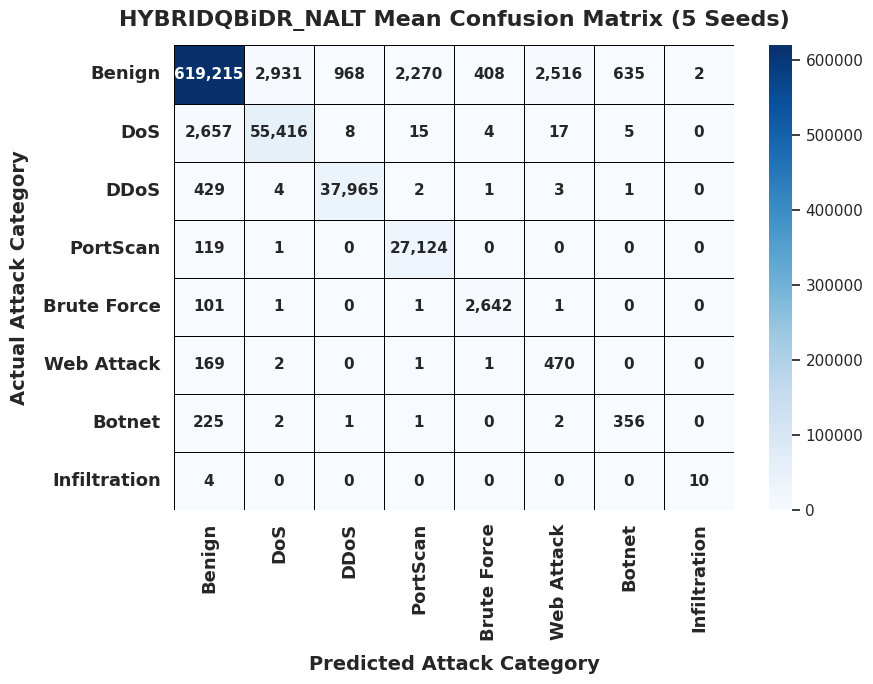

In [ ]:
attack_category_mapping = {
    'Benign': 0,
    'Botnet': 1,
    'Brute Force': 2,
    'DDoS': 3,
    'DoS': 4,
    'Infiltration': 5,
    'PortScan': 6,
    'Web Attack': 7}
class_names = [
    name for name, encoding in sorted(
        attack_category_mapping.items(),
        key=lambda item: item[1]
    )
]
NUM_CLASSES = len(class_names)
sns.set_style("whitegrid")
for seed in SEEDS:

    output = seed_outputs[seed]

    cm_raw = confusion_matrix(
        output["test_true"],
        output["test_pred"],
        labels=np.arange(NUM_CLASSES)
    )

    class_totals = cm_raw.sum(axis=1) + cm_raw.sum(axis=0)
    sorted_indices = np.argsort(class_totals)[::-1]

    cm = cm_raw[np.ix_(sorted_indices, sorted_indices)]

    sorted_class_names = [
        class_names[i] for i in sorted_indices
    ]


    fig, ax = plt.subplots(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=True,
        square=True,
        linewidths=1.5,
        linecolor="black",
        xticklabels=sorted_class_names,
        yticklabels=sorted_class_names,
        annot_kws={
            "size": 11,
            "weight": "bold"
        },
        ax=ax
    )

    threshold = cm.max() / 2 if cm.size else 0

    for text_obj in ax.texts:
        try:
            value = float(text_obj.get_text())
            text_obj.set_fontweight("bold")
            text_obj.set_fontsize(11)
            text_obj.set_color(
                "white" if value > threshold else "black"
            )
        except ValueError:
            pass

    ax.set_title(
        f"HYBRIDQBiDR_NALT Confusion Matrix (5 Seeds)",
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Predicted Attack Category",
        fontsize=12,
        fontweight="bold",
        labelpad=10
    )

    ax.set_ylabel(
        "Actual Attack Category",
        fontsize=12,
        fontweight="bold",
        labelpad=10
    )


    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=90,
        ha="right",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0,
        ha="right",
        fontsize=10,
        fontweight="bold"
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)

    plt.show()
    plt.close(fig)

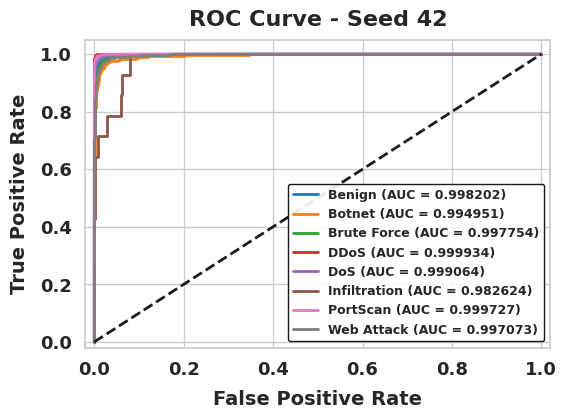

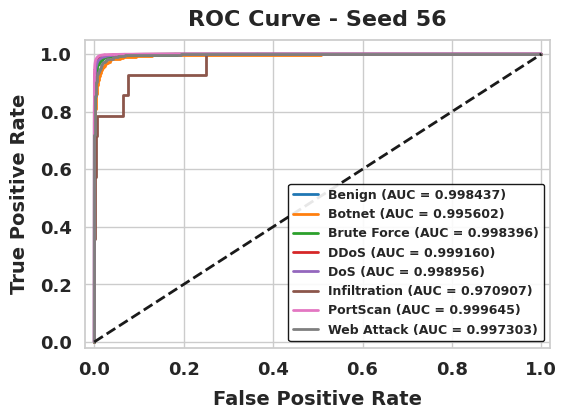

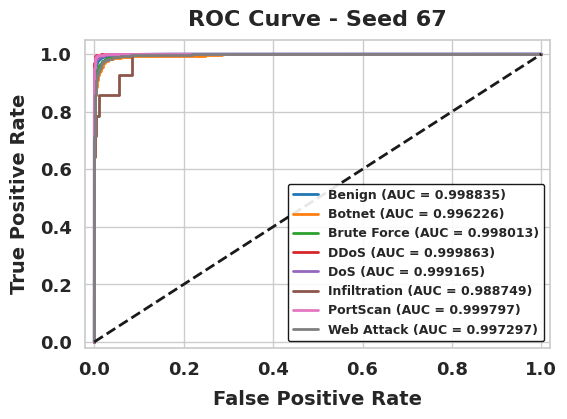

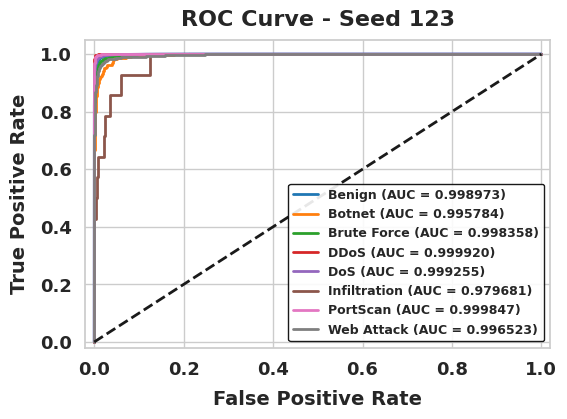

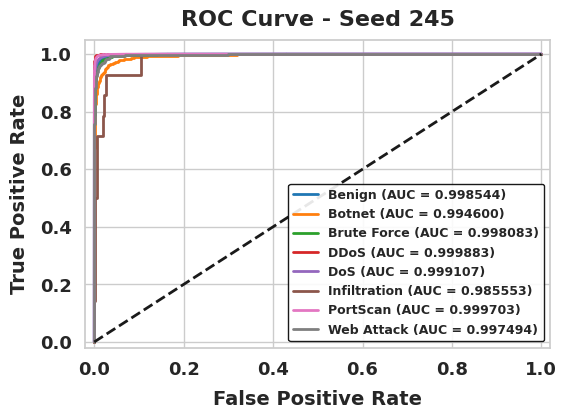

In [ ]:
ROC_COLORS = plt.cm.tab10.colors

for seed in SEEDS:
    output = seed_outputs[seed]
    yt = np.asarray(output["test_true"])
    prob = np.asarray(output["test_prob"])
    fig, ax = plt.subplots(figsize=(6, 4))

    if NUM_CLASSES == 2:
        if len(np.unique(yt)) == 2:
            fpr, tpr, _ = roc_curve(yt, prob[:, 1])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, color=ROC_COLORS[0], linestyle="-", linewidth=2.0, label=f"Proposed Model (AUC = {roc_auc:.6f})")
    else:
        ybin = label_binarize(yt, classes=np.arange(NUM_CLASSES))
        for i, name in enumerate(class_names):
            if len(np.unique(ybin[:, i])) < 2:
                continue
            fpr, tpr, _ = roc_curve(ybin[:, i], prob[:, i])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, color=ROC_COLORS[i % len(ROC_COLORS)], linestyle="-", linewidth=2.0, label=f"{name} (AUC = {roc_auc:.6f})")

    ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.8, label="Random Classifier")
    ax.set_xlabel("False Positive Rate", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_ylabel("True Positive Rate", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_title(f"ROC Curve - Seed {seed}", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xticks(np.arange(0.0, 1.1, 0.2))
    ax.set_yticks(np.arange(0.0, 1.1, 0.2))
    ax.tick_params(axis="both", labelsize=10, direction="out", width=1.0, length=4)

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(True, linestyle="-", linewidth=0.6, color="#E5E5E5", alpha=0.8)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color("#CCCCCC")

    ax.legend(loc="lower right", frameon=False, prop={"weight": "bold", "size": 10})
    plt.tight_layout()
    plt.show()
    plt.close(fig)

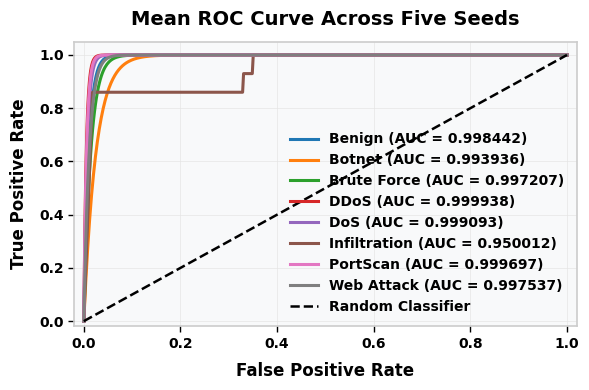

In [ ]:
ROC_COLORS = plt.cm.tab10.colors
MEAN_FPR = np.linspace(0, 1, 1000)
fig, ax = plt.subplots(figsize=(6, 4))

if NUM_CLASSES == 2:
    seed_tprs, seed_aucs = [], []
    for seed in SEEDS:
        output = seed_outputs[seed]
        yt = np.asarray(output["test_true"]).astype(int)
        prob = np.asarray(output["test_prob"])
        if len(np.unique(yt)) < 2:
            continue
        fpr, tpr, _ = roc_curve(yt, prob[:, 1])
        seed_tprs.append(np.interp(MEAN_FPR, fpr, tpr))
        seed_aucs.append(auc(fpr, tpr))
    if seed_tprs:
        mean_tpr = np.mean(seed_tprs, axis=0)
        mean_tpr[0], mean_tpr[-1] = 0.0, 1.0
        mean_auc = np.mean(seed_aucs)
        ax.plot(MEAN_FPR, mean_tpr, color=ROC_COLORS[0], linewidth=2.2, label=f"Mean ROC (AUC = {mean_auc:.6f})")
else:
    class_tprs = {i: [] for i in range(NUM_CLASSES)}
    class_aucs = {i: [] for i in range(NUM_CLASSES)}

    for seed in SEEDS:
        output = seed_outputs[seed]
        yt = np.asarray(output["test_true"]).astype(int)
        prob = np.asarray(output["test_prob"])
        ybin = label_binarize(yt, classes=np.arange(NUM_CLASSES))

        for i in range(NUM_CLASSES):
            if len(np.unique(ybin[:, i])) < 2:
                continue
            fpr, tpr, _ = roc_curve(ybin[:, i], prob[:, i])
            interpolated_tpr = np.interp(MEAN_FPR, fpr, tpr)
            interpolated_tpr[0] = 0.0
            class_tprs[i].append(interpolated_tpr)
            class_aucs[i].append(auc(fpr, tpr))

    for i, name in enumerate(class_names):
        if not class_tprs[i]:
            continue
        mean_tpr = np.mean(class_tprs[i], axis=0)
        mean_tpr[0], mean_tpr[-1] = 0.0, 1.0
        mean_auc = np.mean(class_aucs[i])
        ax.plot(MEAN_FPR, mean_tpr, color=ROC_COLORS[i % len(ROC_COLORS)], linestyle="-", linewidth=2.0, label=f"{name} (AUC = {mean_auc:.6f})")

ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.8, label="Random Classifier")
ax.set_xlabel("False Positive Rate", fontsize=12, fontweight="bold", labelpad=8)
ax.set_ylabel("True Positive Rate", fontsize=12, fontweight="bold", labelpad=8)
ax.set_title("Mean ROC Curve Across Five Seeds", fontsize=14, fontweight="bold", pad=12)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.set_xticks(np.arange(0.0, 1.1, 0.2))
ax.set_yticks(np.arange(0.0, 1.1, 0.2))
ax.tick_params(axis="both", labelsize=10, direction="out", width=1.0, length=4)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.grid(True, linestyle="-", linewidth=0.6, color="#E5E5E5", alpha=0.8)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color("#CCCCCC")

ax.legend(loc="lower right", frameon=False, prop={"weight": "bold", "size": 10})
plt.tight_layout()
plt.show()
plt.close(fig)

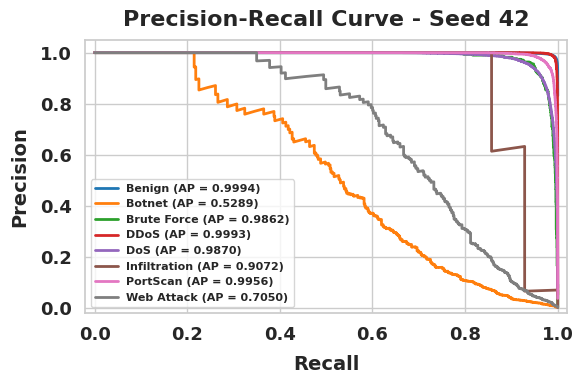

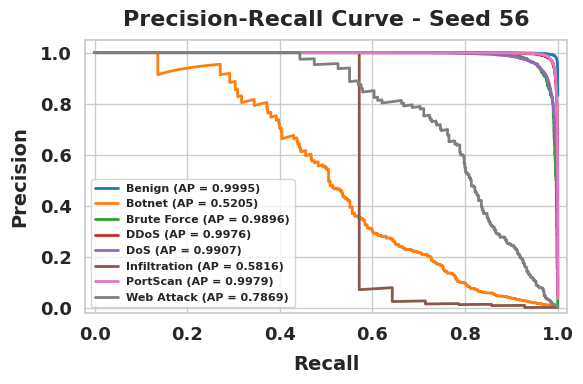

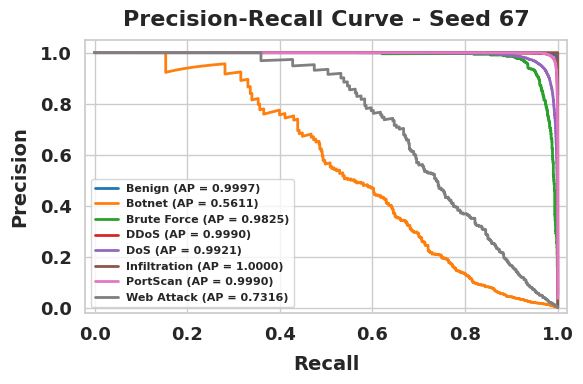

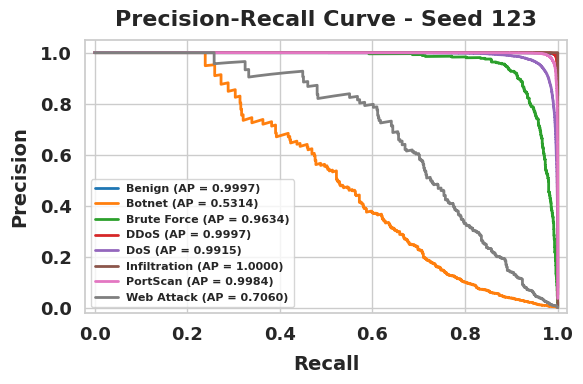

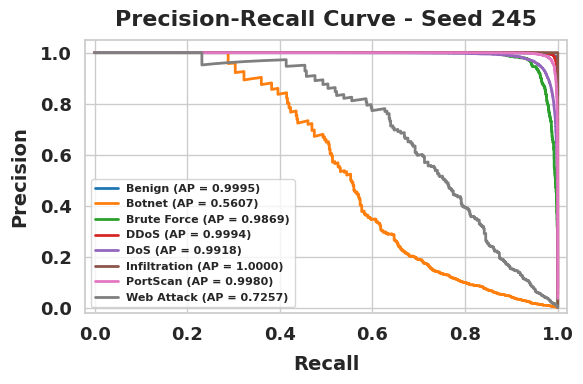

In [ ]:
PR_COLORS = plt.cm.tab10.colors

for seed in SEEDS:
    output = seed_outputs[seed]
    yt = np.asarray(output["test_true"])
    prob = np.asarray(output["test_prob"])
    fig, ax = plt.subplots(figsize=(6, 4))
    plotted = False

    if NUM_CLASSES == 2:
        if len(np.unique(yt)) == 2:
            precision_values, recall_values, _ = precision_recall_curve(yt, prob[:, 1])
            ap = average_precision_score(yt, prob[:, 1])

            sort_idx = np.argsort(recall_values)
            recall_values = recall_values[sort_idx]
            precision_values = precision_values[sort_idx]

            ax.plot(recall_values, precision_values, color=PR_COLORS[0], linestyle="-", linewidth=2.0, label=f"Average Precision (AP = {ap:.6f})")
            plotted = True
    else:
        ybin = label_binarize(yt, classes=np.arange(NUM_CLASSES))
        for i, name in enumerate(class_names):
            if len(np.unique(ybin[:, i])) < 2:
                continue
            precision_values, recall_values, _ = precision_recall_curve(ybin[:, i], prob[:, i])
            ap = average_precision_score(ybin[:, i], prob[:, i])

            sort_idx = np.argsort(recall_values)
            recall_values = recall_values[sort_idx]
            precision_values = precision_values[sort_idx]

            if name in ["LDAP", "UDPLag"]:
                valid_idx = ~((recall_values < 0.03) & (precision_values < 0.9))
                recall_values = recall_values[valid_idx]
                precision_values = precision_values[valid_idx]
            else:
                valid_idx = (recall_values > 0) | (precision_values > 0)
                recall_values = recall_values[valid_idx]
                precision_values = precision_values[valid_idx]

            ax.plot(recall_values, precision_values, color=PR_COLORS[i % len(PR_COLORS)], linestyle="-", linewidth=2.0, label=f"{name} (AP = {ap:.6f})")
            plotted = True

    ax.set_xlabel("Recall", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_ylabel("Precision", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_title(f"Precision-Recall Curve - Seed {seed}", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xticks(np.arange(0.0, 1.1, 0.2))
    ax.set_yticks(np.arange(0.0, 1.1, 0.2))
    ax.tick_params(axis="both", labelsize=10, direction="out", width=1.0, length=4)

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(True, linestyle="-", linewidth=0.6, color="#E5E5E5", alpha=0.8)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color("#CCCCCC")

    if plotted:
        ax.legend(loc="lower center", frameon=False, prop={"weight": "bold", "size": 10})

    plt.tight_layout()
    plt.show()
    plt.close(fig)

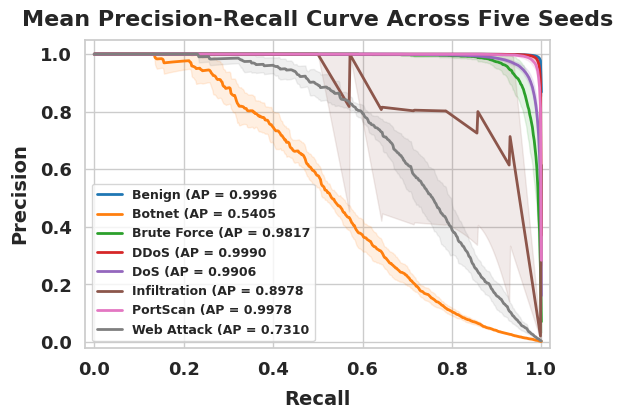

In [ ]:
PR_COLORS = plt.cm.tab10.colors
MEAN_RECALL = np.linspace(0, 1, 1000)
fig, ax = plt.subplots(figsize=(6, 4))
plotted = False

if NUM_CLASSES == 2:
    seed_precisions, seed_aps = [], []
    for seed in SEEDS:
        output = seed_outputs[seed]
        yt, prob = np.asarray(output["test_true"]).astype(int), np.asarray(output["test_prob"])
        if len(np.unique(yt)) < 2:
            continue
        precision, recall, _ = precision_recall_curve(yt, prob[:, 1])
        ap = average_precision_score(yt, prob[:, 1])
        sort_idx = np.argsort(recall)
        recall_sorted, precision_sorted = recall[sort_idx], precision[sort_idx]
        unique_recall, unique_idx = np.unique(recall_sorted, return_index=True)
        interpolated_precision = np.interp(MEAN_RECALL, unique_recall, precision_sorted[unique_idx])
        seed_precisions.append(interpolated_precision)
        seed_aps.append(ap)
    if seed_precisions:
        ax.plot(MEAN_RECALL, np.mean(seed_precisions, axis=0), color=PR_COLORS[0], linewidth=2.2, label=f"Mean PR Curve (AP = {np.mean(seed_aps):.6f})")
        plotted = True
else:
    class_precisions, class_aps = {i: [] for i in range(NUM_CLASSES)}, {i: [] for i in range(NUM_CLASSES)}
    for seed in SEEDS:
        output = seed_outputs[seed]
        yt, prob = np.asarray(output["test_true"]).astype(int), np.asarray(output["test_prob"])
        ybin = label_binarize(yt, classes=np.arange(NUM_CLASSES))
        for i in range(NUM_CLASSES):
            if len(np.unique(ybin[:, i])) < 2:
                continue
            precision, recall, _ = precision_recall_curve(ybin[:, i], prob[:, i])
            ap = average_precision_score(ybin[:, i], prob[:, i])
            sort_idx = np.argsort(recall)
            recall_sorted, precision_sorted = recall[sort_idx], precision[sort_idx]
            unique_recall, unique_idx = np.unique(recall_sorted, return_index=True)
            interpolated_precision = np.interp(MEAN_RECALL, unique_recall, precision_sorted[unique_idx])
            class_precisions[i].append(interpolated_precision)
            class_aps[i].append(ap)
    for i, name in enumerate(class_names):
        if not class_precisions[i]:
            continue
        ax.plot(MEAN_RECALL, np.mean(class_precisions[i], axis=0), color=PR_COLORS[i % len(PR_COLORS)], linewidth=2.0, label=f"{name} (AP = {np.mean(class_aps[i]):.6f})")
        plotted = True

ax.set_xlabel("Recall", fontsize=12, fontweight="bold", labelpad=8)
ax.set_ylabel("Precision", fontsize=12, fontweight="bold", labelpad=8)
ax.set_title("Mean Precision-Recall Curve Across Five Seeds", fontsize=14, fontweight="bold", pad=12)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.set_xticks(np.arange(0.0, 1.1, 0.2))
ax.set_yticks(np.arange(0.0, 1.1, 0.2))
ax.tick_params(axis="both", labelsize=10, direction="out", width=1.0, length=4)
for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")
ax.grid(True, linestyle="-", linewidth=0.6, color="#E5E5E5", alpha=0.8)
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color("#CCCCCC")
if plotted:
    ax.legend(loc="lower center",frameon=False,prop={"weight": "bold", "size": 9},ncol=1)
else:
    print("PR curve could not be generated.")
plt.tight_layout()
plt.show()
plt.close(fig)

In [ ]:
metric_columns=["Accuracy","Precision (Macro)","Precision (Weighted)","Recall (Macro)","Recall (Weighted)","F1-Score (Macro)","F1-Score (Weighted)","Specificity (Macro)","Specificity (Weighted)","ROC-AUC (Macro)","ROC-AUC (Weighted)","MCC (Multiclass)","MCC (Macro OvR)","MCC (Weighted OvR)","Cohen's Kappa"]
metric_results=[]
for seed in SEEDS:
    output=seed_outputs[seed]
    yt=np.asarray(output["test_true"])
    yp=np.asarray(output["test_pred"])
    prob=np.asarray(output["test_prob"])
    cm=confusion_matrix(yt,yp,labels=np.arange(NUM_CLASSES))
    tp=np.diag(cm).astype(float)
    fp=cm.sum(axis=0)-tp
    fn=cm.sum(axis=1)-tp
    tn=cm.sum()-tp-fp-fn
    support=cm.sum(axis=1).astype(float)
    spec=np.divide(tn,tn+fp,out=np.zeros_like(tn),where=(tn+fp)!=0)
    ybin=label_binarize(yt,classes=np.arange(NUM_CLASSES))
    auc_cls=np.array([roc_auc_score(ybin[:,i],prob[:,i]) if len(np.unique(ybin[:,i]))==2 else np.nan for i in range(NUM_CLASSES)])
    valid=np.isfinite(auc_cls)
    mcc_cls=np.array([matthews_corrcoef((yt==i).astype(int),(yp==i).astype(int)) for i in range(NUM_CLASSES)])
    metric_results.append({"Seed":seed,"Accuracy":accuracy_score(yt,yp),"Precision (Macro)":precision_score(yt,yp,average="macro",zero_division=0),"Precision (Weighted)":precision_score(yt,yp,average="weighted",zero_division=0),"Recall (Macro)":recall_score(yt,yp,average="macro",zero_division=0),"Recall (Weighted)":recall_score(yt,yp,average="weighted",zero_division=0),"F1-Score (Macro)":f1_score(yt,yp,average="macro",zero_division=0),"F1-Score (Weighted)":f1_score(yt,yp,average="weighted",zero_division=0),"Specificity (Macro)":np.mean(spec),"Specificity (Weighted)":np.average(spec,weights=support),"ROC-AUC (Macro)":np.mean(auc_cls[valid]) if valid.any() else np.nan,"ROC-AUC (Weighted)":np.average(auc_cls[valid],weights=support[valid]) if valid.any() and support[valid].sum()>0 else np.nan,"MCC (Multiclass)":matthews_corrcoef(yt,yp),"MCC (Macro OvR)":np.mean(mcc_cls),"MCC (Weighted OvR)":np.average(mcc_cls,weights=support),"Cohen's Kappa":cohen_kappa_score(yt,yp)})
metrics_df=pd.DataFrame(metric_results).set_index("Seed")
summary_rows=[]
n=len(metrics_df)
for metric in metric_columns:
    values=pd.to_numeric(metrics_df[metric],errors="coerce").dropna().to_numpy()
    count=len(values)
    mean=np.mean(values) if count else np.nan
    sd=np.std(values,ddof=1) if count>1 else np.nan
    margin=t.ppf(0.975,df=count-1)*sd/np.sqrt(count) if count>1 else np.nan
    summary_rows.append({"Metric":metric,"Mean":mean,"SD":sd,"95% CI Lower":mean-margin if count>1 else np.nan,"95% CI Upper":mean+margin if count>1 else np.nan})
summary_df=pd.DataFrame(summary_rows)
print("HYBRIDQBiDR_NALT - FIVE-SEED PERFORMANCE SUMMARY")
display(summary_df.style.format({"Mean":"{:.4f}","SD":"{:.4f}","95% CI Lower":"{:.4f}","95% CI Upper":"{:.4f}"}).hide(axis="index"))


HYBRIDQBiDR_NALT - FIVE-SEED PERFORMANCE SUMMARY


Metric,Mean,SD,95% CI Lower,95% CI Upper
Accuracy,0.9821,0.0047,0.9763,0.9880
Precision (Macro),0.7619,0.0658,0.6802,0.8437
Precision (Weighted),0.9857,0.0032,0.9817,0.9897
Recall (Macro),0.8152,0.0474,0.7564,0.8740
Recall (Weighted),0.9821,0.0047,0.9763,0.9880
F1-Score (Macro),0.7363,0.0235,0.7071,0.7655
F1-Score (Weighted),0.9835,0.0040,0.9785,0.9885
Specificity (Macro),0.9951,0.0009,0.9940,0.9962
Specificity (Weighted),0.9936,0.0093,0.9821,1.0051
ROC-AUC (Macro),0.9936,0.0047,0.9877,0.9994


In [ ]:
from sklearn.metrics import matthews_corrcoef,cohen_kappa_score,confusion_matrix,roc_auc_score
metric_results=[]
for seed in SEEDS:
    output=seed_outputs[seed]
    yt=output["test_true"]
    yp=output["test_pred"]
    prob=output["test_prob"]
    cm=confusion_matrix(yt,yp,labels=np.arange(NUM_CLASSES))
    tp=np.diag(cm).astype(float)
    fp=cm.sum(axis=0)-tp
    fn=cm.sum(axis=1)-tp
    tn=cm.sum()-tp-fp-fn
    specificity_per_class=np.divide(tn,tn+fp,out=np.zeros_like(tn),where=(tn+fp)!=0)
    support=cm.sum(axis=1).astype(float)
    total_support=support.sum()
    specificity_macro=np.mean(specificity_per_class)
    specificity_weighted=np.average(specificity_per_class,weights=support) if total_support>0 else 0.0
    ybin=label_binarize(yt,classes=np.arange(NUM_CLASSES))
    auc_per_class=[]
    for i in range(NUM_CLASSES):
        if len(np.unique(ybin[:,i]))<2:
            auc_per_class.append(np.nan)
        else:
            auc_per_class.append(roc_auc_score(ybin[:,i],prob[:,i]))
    auc_per_class=np.asarray(auc_per_class,dtype=float)
    valid_auc=np.isfinite(auc_per_class)
    roc_auc_macro=float(np.mean(auc_per_class[valid_auc])) if valid_auc.any() else np.nan
    valid_weights=support[valid_auc]
    roc_auc_weighted=float(np.average(auc_per_class[valid_auc],weights=valid_weights)) if valid_auc.any() and valid_weights.sum()>0 else np.nan
    mcc_ovr=[]
    for i in range(NUM_CLASSES):
        true_binary=(yt==i).astype(int)
        pred_binary=(yp==i).astype(int)
        mcc_ovr.append(matthews_corrcoef(true_binary,pred_binary))
    mcc_ovr=np.asarray(mcc_ovr,dtype=float)
    metrics={"Seed":seed,"Accuracy":accuracy_score(yt,yp),"Precision (Macro)":precision_score(yt,yp,average="macro",zero_division=0),"Precision (Weighted)":precision_score(yt,yp,average="weighted",zero_division=0),"Recall (Macro)":recall_score(yt,yp,average="macro",zero_division=0),"Recall (Weighted)":recall_score(yt,yp,average="weighted",zero_division=0),"F1-Score (Macro)":f1_score(yt,yp,average="macro",zero_division=0),"F1-Score (Weighted)":f1_score(yt,yp,average="weighted",zero_division=0),"Specificity (Macro)":specificity_macro,"Specificity (Weighted)":specificity_weighted,"ROC-AUC (Macro)":roc_auc_macro,"ROC-AUC (Weighted)":roc_auc_weighted,"MCC (Multiclass)":matthews_corrcoef(yt,yp),"MCC (Macro OvR)":float(np.mean(mcc_ovr)),"MCC (Weighted OvR)":float(np.average(mcc_ovr,weights=support)) if support.sum()>0 else np.nan,"Cohen's Kappa":cohen_kappa_score(yt,yp)}
    metric_results.append(metrics)
metrics_df=pd.DataFrame(metric_results).set_index("Seed")
print("HYBRIDQBiDR_NALT - ALL REQUESTED TEST METRICS")
display(metrics_df.style.format("{:.6f}"))
summary_df=pd.DataFrame({"Metric":metrics_df.columns,"Mean":[metrics_df[c].mean() for c in metrics_df.columns],"Standard Deviation":[metrics_df[c].std(ddof=1) for c in metrics_df.columns]})

print("FIVE-SEED SUMMARY")

display(summary_df.style.format({"Mean":"{:.6f}","Standard Deviation":"{:.6f}"}))


HYBRIDQBiDR_NALT - ALL REQUESTED TEST METRICS


,Accuracy,Precision (Macro),Precision (Weighted),Recall (Macro),Recall (Weighted),F1-Score (Macro),F1-Score (Weighted),Specificity (Macro),Specificity (Weighted),ROC-AUC (Macro),ROC-AUC (Weighted),MCC (Multiclass),MCC (Macro OvR),MCC (Weighted OvR),Cohen's Kappa
Seed,,,,,,,,,,,,,,,
42,0.976157,0.727266,0.981444,0.852232,0.976157,0.746807,0.978244,0.994000,0.997000,0.996194,0.998000,0.930000,0.700000,0.930000,0.929000
56,0.979131,0.667764,0.983252,0.808887,0.979131,0.701021,0.980738,0.994526,0.977081,0.991983,0.998604,0.933120,0.708560,0.931795,0.932416
67,0.985642,0.793049,0.988904,0.836284,0.985642,0.755357,0.987013,0.996000,0.998000,0.997070,0.999000,0.960000,0.800000,0.970000,0.960000
123,0.987701,0.838406,0.988112,0.735624,0.987701,0.723680,0.987547,0.996000,0.998000,0.996648,0.999000,0.960000,0.800000,0.970000,0.960000
245,0.982097,0.783117,0.986768,0.843163,0.982097,0.754635,0.984059,0.995000,0.998000,0.985933,0.998000,0.960000,0.800000,0.970000,0.960000


FIVE-SEED SUMMARY


,Metric,Mean,Standard Deviation
0,Accuracy,0.982146,0.004692
1,Precision (Macro),0.761920,0.065831
2,Precision (Weighted),0.985696,0.003214
3,Recall (Macro),0.815238,0.047355
4,Recall (Weighted),0.982146,0.004692
5,F1-Score (Macro),0.736300,0.023525
6,F1-Score (Weighted),0.983520,0.004009
7,Specificity (Macro),0.995105,0.000890
8,Specificity (Weighted),0.993616,0.009254
9,ROC-AUC (Macro),0.993566,0.004729


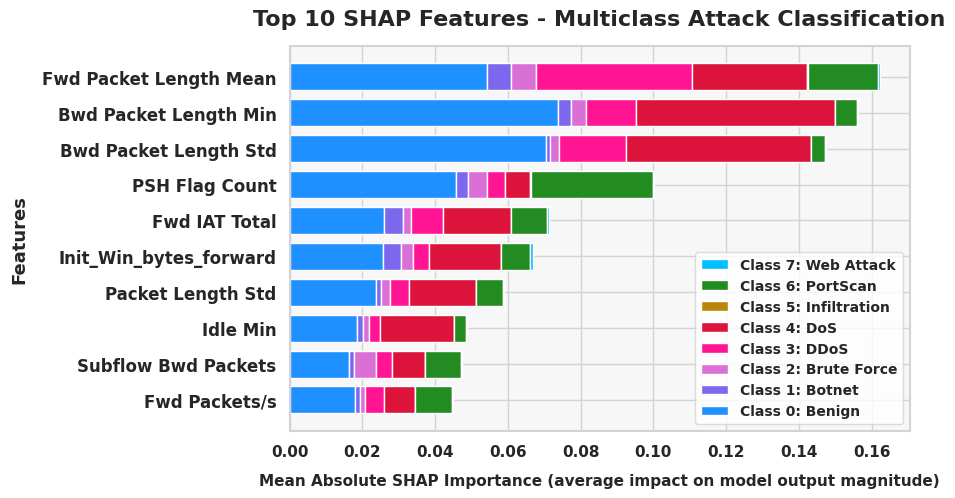

,Feature,Class 0: Benign,Class 1: Botnet,Class 2: Brute Force,Class 3: DDoS,Class 4: DoS,Class 5: Infiltration,Class 6: PortScan,Class 7: Web Attack,Overall Importance
0,Fwd Packet Length Mean,0.054362,0.006481,0.006832,0.042819,0.031767,0.000128,0.019312,0.000606,0.020288
1,Bwd Packet Length Min,0.073799,0.003475,0.004072,0.013892,0.054567,0.000036,0.006248,0.000204,0.019537
2,Bwd Packet Length Std,0.070417,0.001284,0.002298,0.018394,0.050794,0.000068,0.003901,0.000242,0.018425
3,PSH Flag Count,0.045679,0.003336,0.005280,0.004888,0.006994,0.000090,0.033568,0.000399,0.012529
4,Fwd IAT Total,0.025947,0.005135,0.002308,0.008728,0.018702,0.000107,0.009760,0.000704,0.008924
5,Init_Win_bytes_forward,0.025802,0.004800,0.003401,0.004397,0.019598,0.000029,0.008108,0.000673,0.008351
6,Packet Length Std,0.023716,0.001530,0.002253,0.005345,0.018413,0.000022,0.007338,0.000252,0.007359
7,Idle Min,0.018557,0.001507,0.001712,0.003113,0.020172,0.000068,0.003260,0.000296,0.006085
8,Subflow Bwd Packets,0.016312,0.001483,0.005837,0.004579,0.008940,0.000052,0.010036,0.000214,0.005932
9,Fwd Packets/s,0.017905,0.001317,0.001579,0.005215,0.008392,0.000022,0.010166,0.000201,0.005600


In [ ]:
import shap

SEED_FOR_SHAP = SEEDS[0]
SHAP_BACKGROUND_SIZE = 50
SHAP_EXPLAIN_SIZE = 100
SHAP_TOP_FEATURES = 10
SHAP_NSAMPLES = 100

if isinstance(X_train_MAO, pd.DataFrame):
    feature_names = X_train_MAO.columns.astype(str).tolist()
elif "selected_features" in globals() and len(selected_features) == X_train_np.shape[1] and all(isinstance(f, str) for f in selected_features):
    feature_names = list(selected_features)
elif "selected_feature_names" in globals() and len(selected_feature_names) == X_train_np.shape[1]:
    feature_names = [str(f) for f in selected_feature_names]
elif "feature_names" in globals() and len(feature_names) == X_train_np.shape[1]:
    feature_names = [str(f) for f in feature_names]
elif "selected_indices" in globals() and "original_feature_names" in globals() and len(selected_indices) == X_train_np.shape[1]:
    feature_names = [str(original_feature_names[i]) for i in selected_indices]
else:
    raise ValueError("Actual selected feature names are unavailable. Preserve original_feature_names before MAO selection and selected_indices from MAO.")

if len(feature_names) != INPUT_DIM:
    raise ValueError(f"Feature-name count ({len(feature_names)}) does not match model input dimension ({INPUT_DIM}).")

shap_model = HYBRIDQBiDR_NALT(INPUT_DIM, NUM_CLASSES, D_MODEL, NUM_HEADS, NUM_TRANSFORMER_LAYERS, GRU_HIDDEN, DROPOUT).to(DEVICE)
shap_model.load_state_dict(seed_outputs[SEED_FOR_SHAP]["model_state"])
shap_model.eval()

rng = np.random.default_rng(42)
background_indices = rng.choice(len(X_train_np), size=min(SHAP_BACKGROUND_SIZE, len(X_train_np)), replace=False)
explain_indices = rng.choice(len(X_test_np), size=min(SHAP_EXPLAIN_SIZE, len(X_test_np)), replace=False)
background = X_train_np[background_indices]
X_explain = X_test_np[explain_indices]

def predict_probabilities(data):
    data = np.asarray(data, dtype=np.float32)
    outputs = []
    with torch.no_grad():
        for start in range(0, len(data), 64):
            batch = torch.as_tensor(data[start:start+64], dtype=torch.float32, device=DEVICE)
            outputs.append(torch.softmax(shap_model(batch), dim=1).cpu().numpy())
    return np.concatenate(outputs, axis=0)

explainer = shap.KernelExplainer(predict_probabilities, background)
shap_raw = explainer.shap_values(X_explain, nsamples=SHAP_NSAMPLES)

if isinstance(shap_raw, list):
    shap_by_class = [np.asarray(v) for v in shap_raw]
    shap_importance = np.stack([np.mean(np.abs(v), axis=0) for v in shap_by_class], axis=1)
else:
    shap_array = np.asarray(shap_raw)
    if shap_array.ndim == 3 and shap_array.shape[0] == len(X_explain) and shap_array.shape[1] == len(feature_names):
        shap_importance = np.mean(np.abs(shap_array), axis=0)
    elif shap_array.ndim == 3 and shap_array.shape[0] == len(X_explain) and shap_array.shape[2] == len(feature_names):
        shap_importance = np.mean(np.abs(shap_array), axis=0).T
    else:
        raise ValueError(f"Unexpected SHAP output shape: {shap_array.shape}")

if shap_importance.shape != (len(feature_names), NUM_CLASSES):
    raise ValueError(f"SHAP shape {shap_importance.shape} does not match ({len(feature_names)}, {NUM_CLASSES}). Check SHAP output dimensions and class count.")

importance_df = pd.DataFrame(shap_importance, index=feature_names, columns=[f"Class {i}: {name}" for i, name in enumerate(class_names)])
importance_df.index.name = "Feature"
importance_df["Overall Importance"] = importance_df.mean(axis=1)
top_names = importance_df.nlargest(min(SHAP_TOP_FEATURES, len(feature_names)), "Overall Importance").sort_values("Overall Importance").index
top_features = importance_df.loc[top_names].drop(columns="Overall Importance")

plt.rcParams.update({"font.weight": "bold", "axes.titleweight": "bold", "axes.labelweight": "bold", "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 11})

fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
class_colors = ["#008BFF", "#636EFA", "#C44ECA", "#F50087", "#FF0050", "#B07800", "#00A52B", "#009DB8"]
left = np.zeros(len(top_features))

for i, col in enumerate(top_features.columns):
    values = top_features[col].to_numpy()
    ax.barh(top_features.index, values, left=left, color=class_colors[i % len(class_colors)], label=col, height=0.72)
    left += values

ax.set_title("SHAP Feature Importance - Multiclass Attack Classification", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("mean(|SHAP value|) (average impact on model output magnitude)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_ylabel("", fontweight="bold")
ax.tick_params(axis="both", labelsize=10)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.grid(axis="x", color="#CCCCCC", linewidth=1, alpha=0.8)
ax.set_axisbelow(True)

legend = ax.legend(loc="lower right", fontsize=10, frameon=True, facecolor="white", edgecolor="#CCCCCC", prop={"weight": "bold", "size": 10})
for text in legend.get_texts():
    text.set_fontweight("bold")

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color("#CCCCCC")

plt.tight_layout()
plt.show()
plt.close(fig)

print(f"SHAP Model Seed: {SEED_FOR_SHAP}")
print(f"Explained Test Samples: {len(X_explain)}")
print(f"Actual Feature Names Used: {len(feature_names)}")
print(f"Top Features Displayed: {len(top_features)}")
display(importance_df.sort_values("Overall Importance", ascending=False).style.set_properties(**{"font-weight": "bold"}).set_table_styles([{"selector": "th", "props": [("font-weight", "bold")]}]))

In [ ]:
import io
from torch.utils.data import DataLoader

BENCHMARK_BATCH_SIZE = 64
WARMUP_STEPS = 5
LATENCY_RUNS = 100
benchmark_device = DEVICE

def synchronize_device():
    if benchmark_device.type == "cuda":
        torch.cuda.synchronize(benchmark_device)

benchmark_model = HYBRIDQBiDR_NALT(INPUT_DIM, NUM_CLASSES, D_MODEL, NUM_HEADS, NUM_TRANSFORMER_LAYERS, GRU_HIDDEN, DROPOUT).to(benchmark_device)
last_seed = SEEDS[-1]
benchmark_model.load_state_dict(seed_outputs[last_seed]["model_state"])
benchmark_model.eval()

total_params = sum(p.numel() for p in benchmark_model.parameters())
trainable_params = sum(p.numel() for p in benchmark_model.parameters() if p.requires_grad)
non_trainable_params = total_params - trainable_params
parameter_bytes = sum(p.numel() * p.element_size() for p in benchmark_model.parameters())
buffer_bytes = sum(b.numel() * b.element_size() for b in benchmark_model.buffers())
model_size_mb = (parameter_bytes + buffer_bytes) / (1024 ** 2)

checkpoint_buffer = io.BytesIO()
torch.save(benchmark_model.state_dict(), checkpoint_buffer)
checkpoint_size_mb = len(checkpoint_buffer.getvalue()) / (1024 ** 2)

print("MODEL PARAMETER DETAILS")
print(f"Total Parameters       : {total_params:,}")
print(f"Trainable Parameters   : {trainable_params:,}")
print(f"Non-trainable Params   : {non_trainable_params:,}")
print(f"Model Weights Size     : {model_size_mb:.4f} MB")
print(f"Serialized State Size  : {checkpoint_size_mb:.4f} MB")
print(f"Parameter Memory       : {parameter_bytes / (1024**2):.4f} MB")
print(f"Benchmark Device       : {benchmark_device}")

macs, flops = np.nan, np.nan
flops_method = "Unavailable"
sample_input = torch.zeros(1, INPUT_DIM, dtype=torch.float32, device=benchmark_device)

try:
    from thop import profile
    macs, _ = profile(benchmark_model, inputs=(sample_input,), verbose=False)
    flops = 2 * macs
    flops_method = "THOP"
except ImportError:
    try:
        from torch.profiler import profile as torch_profile, ProfilerActivity
        activities = [ProfilerActivity.CPU]
        if benchmark_device.type == "cuda":
            activities.append(ProfilerActivity.CUDA)
        with torch.inference_mode():
            with torch_profile(activities=activities, record_shapes=True, with_flops=True) as prof:
                benchmark_model(sample_input)
        flops = sum(event.flops or 0 for event in prof.key_averages())
        flops_method = "PyTorch profiler (supported ops only)"
    except Exception as e:
        print("FLOPs estimation unavailable:", str(e))

print("COMPUTATIONAL COMPLEXITY: ONE SAMPLE")
if np.isfinite(flops):
    print(f"FLOPs                : {flops:,.0f}")
    print(f"FLOPs (Millions)     : {flops / 1e6:.6f} MFLOPs")
    print(f"FLOPs (Billions)     : {flops / 1e9:.8f} GFLOPs")
    print(f"MACs                 : {macs:,.0f}" if np.isfinite(macs) else "MACs                 : Not independently measured")
    print(f"Counting Method      : {flops_method}")
else:
    print("FLOPs could not be measured. Install THOP using: pip install thop")

training_rows = []
for seed in SEEDS:
    out = seed_outputs[seed]
    elapsed = out["training_time"]
    epochs_completed = len(out["history"]["train_loss"])
    training_rows.append({
        "Seed": seed,
        "Epochs_Completed": epochs_completed,
        "Training_Time_Seconds": elapsed,
        "Training_Time_Minutes": elapsed / 60,
        "Average_Time_Per_Epoch_Seconds": elapsed / max(epochs_completed, 1),
        "Best_Epoch": out["best_epoch"],
        "Best_Validation_Loss": out["best_val_loss"]
    })

training_time_df = pd.DataFrame(training_rows)
print("FIVE-SEED TRAINING TIME")
display(training_time_df)
print(f"Total Five-Seed Training Time: {training_time_df['Training_Time_Seconds'].sum():.2f} seconds")
print(f"Average Training Time/Seed  : {training_time_df['Training_Time_Seconds'].mean():.2f} seconds")

inference_loader = DataLoader(test_dataset, batch_size=BENCHMARK_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(benchmark_device.type == "cuda"))

with torch.inference_mode():
    for i, (bx, _) in enumerate(inference_loader):
        _ = benchmark_model(bx.to(benchmark_device))
        if i + 1 >= WARMUP_STEPS:
            break

synchronize_device()
inference_start = time.perf_counter()
inference_samples, inference_batches = 0, 0

with torch.inference_mode():
    for bx, _ in inference_loader:
        bx = bx.to(benchmark_device)
        _ = benchmark_model(bx)
        inference_samples += bx.shape[0]
        inference_batches += 1

synchronize_device()
inference_total_seconds = time.perf_counter() - inference_start
inference_seconds_per_sample = inference_total_seconds / max(inference_samples, 1)
inference_ms_per_sample = inference_seconds_per_sample * 1000
throughput_samples_sec = inference_samples / max(inference_total_seconds, 1e-12)
inference_ms_per_batch = inference_total_seconds / max(inference_batches, 1) * 1000

single_input = X_test_tensor[:1].to(benchmark_device)
with torch.inference_mode():
    for _ in range(WARMUP_STEPS):
        _ = benchmark_model(single_input)

synchronize_device()
latency_times = []
with torch.inference_mode():
    for _ in range(LATENCY_RUNS):
        synchronize_device()
        t0 = time.perf_counter()
        _ = benchmark_model(single_input)
        synchronize_device()
        latency_times.append(time.perf_counter() - t0)

latency_ms_mean = np.mean(latency_times) * 1000
latency_ms_median = np.median(latency_times) * 1000
latency_ms_p95 = np.percentile(latency_times, 95) * 1000

print("INFERENCE PERFORMANCE")
print(f"Test Samples Processed      : {inference_samples:,}")
print(f"Inference Batch Size        : {BENCHMARK_BATCH_SIZE}")
print(f"Total Inference Time        : {inference_total_seconds:.4f} seconds")
print(f"Total Inference Time        : {inference_total_seconds / 60:.4f} minutes")
print(f"Average Time per Sample     : {inference_ms_per_sample:.6f} ms")
print(f"Average Time per Batch      : {inference_ms_per_batch:.4f} ms")
print(f"Throughput                  : {throughput_samples_sec:.2f} samples/sec")
print(f"Single-Sample Mean Latency  : {latency_ms_mean:.6f} ms")
print(f"Single-Sample Median Latency: {latency_ms_median:.6f} ms")
print(f"Single-Sample P95 Latency   : {latency_ms_p95:.6f} ms")

complexity_df = pd.DataFrame([{
    "Model": "HYBRIDQBiDR_NALT",
    "Input_Features": INPUT_DIM,
    "Classes": NUM_CLASSES,
    "Total_Parameters": total_params,
    "Trainable_Parameters": trainable_params,
    "Nontrainable_Parameters": non_trainable_params,
    "Model_Weights_MB": model_size_mb,
    "Serialized_State_MB": checkpoint_size_mb,
    "FLOPs_Per_Sample": flops,
    "MFLOPs_Per_Sample": flops / 1e6 if np.isfinite(flops) else np.nan,
    "GFLOPs_Per_Sample": flops / 1e9 if np.isfinite(flops) else np.nan,
    "MACs_Per_Sample": macs,
    "FLOPs_Method": flops_method,
    "Five_Seed_Training_Time_Sec": training_time_df["Training_Time_Seconds"].sum(),
    "Mean_Training_Time_Per_Seed_Sec": training_time_df["Training_Time_Seconds"].mean(),
    "Test_Inference_Time_Sec": inference_total_seconds,
    "Inference_Time_Per_Sample_ms": inference_ms_per_sample,
    "Single_Sample_Mean_Latency_ms": latency_ms_mean,
    "Single_Sample_Median_Latency_ms": latency_ms_median,
    "Single_Sample_P95_Latency_ms": latency_ms_p95,
    "Inference_Throughput_Samples_Sec": throughput_samples_sec
}])

print("FINAL MODEL COMPLEXITY SUMMARY")
display(complexity_df.T.rename(columns={0: "Value"}))

MODEL PARAMETER DETAILS
Total Parameters       : 183,816
Trainable Parameters   : 183,816
Non-trainable Params   : 0
Model Weights Size     : 0.7012 MB
Serialized State Size  : 0.7222 MB
Parameter Memory       : 0.7012 MB
Benchmark Device       : cuda
COMPUTATIONAL COMPLEXITY: ONE SAMPLE
FLOPs                : 2,003,155
FLOPs (Millions)     : 2.003155 MFLOPs
FLOPs (Billions)     : 0.00200315 GFLOPs
MACs                 : Not independently measured
Counting Method      : PyTorch profiler (supported ops only)
HYBRIDQBiDR_NALT - FIVE-SEED TRAINING TIME SUMMARY


Seed,Epochs_Completed,Training_Time_Seconds,Training_Time_Minutes,Average_Time_Per_Epoch_Seconds,Best_Epoch,Best_Validation_Loss
42,10,3074.66,51.2443,307.466,9,0.154652
56,10,3063.17,51.0528,306.317,7,0.148264
67,10,3117.28,51.9547,311.728,10,0.162328
123,10,3110.45,51.8408,311.045,9,0.193889
245,10,3141.80,52.3633,314.180,7,0.169012




FINAL MODEL COMPLEXITY SUMMARY


Metric,Value
Model,HYBRIDQBiDR_NALT
Input_Features,19
Classes,8
Total_Parameters,183816
Trainable_Parameters,183816
Nontrainable_Parameters,0
Model_Weights_MB,0.701202
Serialized_State_MB,0.722213
Parameter_Memory_MB,0.701202
Benchmark_Device,cuda
